# Case Study: Analyzing Bumble Profiles
## Background
Bumble is a popular dating platform where users connect based on mutual interests and compatibility. To provide a better matchmaking experience, Bumble collects user information through profiles, which include details about demographics, lifestyle habits, and personal preferences.

This dataset represents user-generated profiles, offering a rich source of information to understand user behavior, preferences, and trends.

## Goal
You have been given the task of analyzing the Bumble dataset to answer key business and user behavior questions. Your objectives are to:

 Clean the Data:
Identify and handle missing values, duplicates, and incorrect data types.

Address outliers in numerical columns like age, height, and income.

 Process the Data:
Create new features, such as the number of days since a user was last online.

Standardize and scale numerical columns for better comparison.

Group ages into categories to better understand user demographics.

 Explore the Data:
Investigate the distribution of users by demographics, such as gender, location, and preferences.

Analyze relationships between lifestyle habits (e.g., diet, smoking, drinking).

Explore correlations between variables like age, income, and profile essay lengths.

 Visualize the Data:
Create charts and graphs to communicate your findings effectively.

Use bar charts, scatterplots, histograms, and heatmaps to uncover trends.

# Part 1: Data Cleaning
## 1 Inspecting Missing Data
Missing data is a common issue in real-world datasets. On a platform like Bumble, missing user information might reflect gaps in the user profile setup process, incomplete data collection, or users intentionally leaving certain fields blank. As a data analyst, your role is to assess the extent of missing data, understand its potential impact, and decide the most appropriate methods to address it.




## Importing Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('bumble.csv')

In [187]:
df_org = pd.read_csv('bumble.csv')

In [5]:
df.head()

,age,status,gender,body_type,diet,drinks,education,ethnicity,height,income,job,last_online,location,pets,religion,sign,speaks
0,22,single,m,a little extra,strictly anything,socially,working on college/university,"asian, white",75.0,-1,transportation,2012-06-28-20-30,"south san francisco, california",likes dogs and likes cats,agnosticism and very serious about it,gemini,english
1,35,single,m,average,mostly other,often,working on space camp,white,70.0,80000,hospitality / travel,2012-06-29-21-41,"oakland, california",likes dogs and likes cats,agnosticism but not too serious about it,cancer,"english (fluently), spanish (poorly), french (..."
2,38,available,m,thin,anything,socially,graduated from masters program,NaN,68.0,-1,NaN,2012-06-27-09-10,"san francisco, california",has cats,NaN,pisces but it doesn&rsquo;t matter,"english, french, c++"
3,23,single,m,thin,vegetarian,socially,working on college/university,white,71.0,20000,student,2012-06-28-14-22,"berkeley, california",likes cats,NaN,pisces,"english, german (poorly)"
4,29,single,m,athletic,NaN,socially,graduated from college/university,"asian, black, other",66.0,-1,artistic / musical / writer,2012-06-27-21-26,"san francisco, california",likes dogs and likes cats,NaN,aquarius,english


## Q1.1
Which columns in the dataset have missing values, and what percentage of data is missing in each column?



In [7]:
df.isnull().sum().sort_values(ascending=False)

diet           24395
religion       20226
pets           19921
sign           11056
job             8198
education       6628
ethnicity       5680
body_type       5296
drinks          2985
speaks            50
height             3
last_online        0
location           0
income             0
status             0
gender             0
age                0
dtype: int64

In [94]:
(df.isnull().sum()/len(df)*100).sort_values(ascending=False).round(2).reset_index()

,index,0
0,diet,40.69
1,religion,33.74
2,pets,33.23
3,sign,18.44
4,job,13.68
5,education,11.06
6,ethnicity,9.48
7,body_type,8.83
8,drinks,4.98
9,speaks,0.08


Columns with the highest missing values are:-
1. diet -- 40%
2. religion -- 33%
3. pets -- 33%
4. sign -- 18%

 ## Q1.2
 Are there columns where more than 50% of the data is missing? Would you drop those columns where missing values are >50%. If yes, why?


In [24]:
(df.isnull().sum()/len(df)*100).sort_values(ascending=False).round(2).reset_index()

,index,0
0,diet,40.69
1,religion,33.74
2,pets,33.23
3,sign,18.44
4,job,13.68
5,education,11.06
6,ethnicity,9.48
7,body_type,8.83
8,drinks,4.98
9,speaks,0.08


There are no columns where more than 50% of values are missing. Eventhough if there were such columns either i will treat them as per the needs of my
analysis or just keep them droping columns is a extreme step which should be taken when the column is absolutly of no use(but I would not preffer that)

## Q1.3
How would you handle the missing numerical data (e.g., height, income)? Would you impute the missing data by the median or average value of height and income for the corresponding category, such as gender, age group, or location. If yes, why?



In [58]:
# checking the null in the age columns
df['age'].isnull().sum()

0

In [60]:
# checking the null in the height columns
df['height'].isnull().sum() #By mistake executed this cell again that's why sum of null is 0

0

In [53]:
# checking the null in the income columns
df.income.isnull().sum()

0

In numerical column except height other numerical does not contain null valuse and height only containes 3 missing valuse so i will replace them with median.

In [57]:
df.height =df.height.fillna(df.height.median())

In [70]:
df.income.value_counts() 

income
-1          48442
 20000       2952
 100000      1621
 80000       1111
 30000       1048
 40000       1005
 50000        975
 60000        736
 70000        707
 150000       631
 1000000      521
 250000       149
 500000        48
Name: count, dtype: int64

Due to system error null is treated as -1 in the income.

In [85]:
# checking the count and share of -1 in the income column
print(f'count of -1 are: {len(df.query("income==-1"))}')
print(f'Percentage of -1 are: {round(100*len(df.query("income==-1"))/len(df),2)}')

count of -1 are: 48442
Percentage of -1 are: 80.81


80% of the values are missing in the income column and thinking from the general or users point of view not everyone is comfortable in sharing their exact salary on dating platform or any othe platform 

In [103]:
# non columns with nulls
# categorical columns with null are being replaced with the Unknown.
# not treating Speaks column cause it has below 1% null valuse that wouldn't effect the analysis
cat_cols = [
    'diet', 'religion', 'pets', 'sign', 'job',
    'education', 'ethnicity', 'body_type', 'drinks'
]
df[cat_cols] = df[cat_cols].fillna("Unknown")


In [104]:
df.isnull().sum().sort_values(ascending=False)

speaks         50
income          0
sign            0
religion        0
pets            0
location        0
last_online     0
job             0
age             0
status          0
ethnicity       0
education       0
drinks          0
diet            0
body_type       0
gender          0
height          0
dtype: int64

# 2. Data Types
Accurate data types are critical for meaningful analysis and visualization. For example, numeric fields like income or height must be stored as numbers for statistical computations, while dates like last_online must be converted to datetime format for time-based calculations.

## Q2.1
Are there any inconsistencies in the data types across columns (e.g., numerical data stored as strings)?

In [107]:
 df.info() #every columns data is perfect except last_online it's dtype is object.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59946 entries, 0 to 59945
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          59946 non-null  int64  
 1   status       59946 non-null  object 
 2   gender       59946 non-null  object 
 3   body_type    59946 non-null  object 
 4   diet         59946 non-null  object 
 5   drinks       59946 non-null  object 
 6   education    59946 non-null  object 
 7   ethnicity    59946 non-null  object 
 8   height       59946 non-null  float64
 9   income       59946 non-null  int64  
 10  job          59946 non-null  object 
 11  last_online  59946 non-null  object 
 12  location     59946 non-null  object 
 13  pets         59946 non-null  object 
 14  religion     59946 non-null  object 
 15  sign         59946 non-null  object 
 16  speaks       59896 non-null  object 
dtypes: float64(1), int64(2), object(14)
memory usage: 7.8+ MB


## Q2.2
Which columns require conversion to numerical data types for proper analysis (e.g., income)?
1. All the columns in the data seems perfect in terms to assigned dtypes 

## Q2.3
Does the last_online column need to be converted into a datetime format? What additional insights can be gained by analyzing this as a date field?

In [115]:
df['last_online']=pd.to_datetime(df['last_online'],format='%Y-%m-%d-%H-%M')

Converting the last_online column to datetime cause it will give us valualbe insights about the users and for how long they used the app and what was the list time they used the app and also in the time based analysis

# 3. Outliers
Outliers are extreme values in the dataset that can distort averages, correlations, and overall trends. In the context of Bumble, an outlier in age (e.g., 110 years old) or income (e.g., $1,000,000 or -1) could represent errors or rare, invalid cases.



## Q3.1
Are there any apparent outliers in numerical columns such as age, height, or income? What are the ranges of values in these columns?



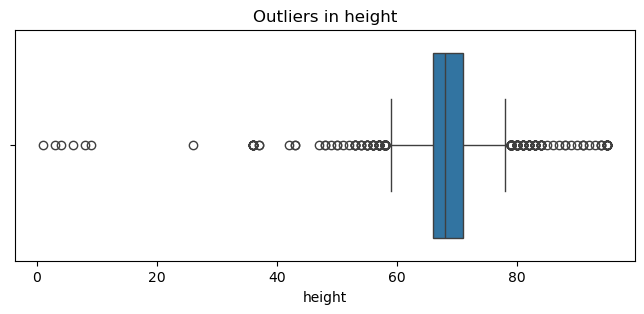

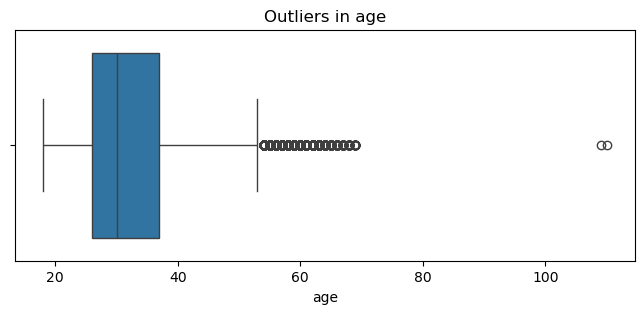

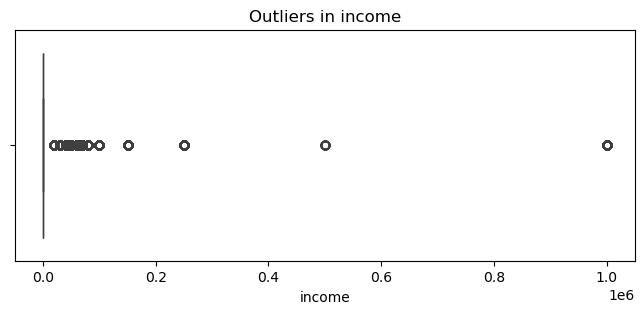

In [133]:
#Creating boxplot for every numerical column to get a better idea abbout the outliers
num_cols = ['height','age','income']
for cols in num_cols:
    plt.figure(figsize=(8,3))
    sns.boxplot(x = df[cols])
    plt.title(f'Outliers in {cols}')
    plt.show()

In [178]:
# using IQR to get the range to detect outliers in the columns
def outlier_detection(df, col_name):
    Q1  = df[col_name].quantile(.25)
    Q3  = df[col_name].quantile(.75)
    IQR = Q3-Q1
    higher_fence = Q3+1.5*IQR
    lower_fence = Q1-1.5*IQR
    print( f'Higher Fence for {col_name} is {higher_fence}\n',
         f'Lower Fence for {col_name} is {lower_fence}')
    total_outliers = df[(df[col_name]<lower_fence) | (df[col_name]>higher_fence)].shape[0]
    print(f"Total outlier rows detected: {total_outliers}\n")
    

## Q3.2
Any -1 values in numerical columns like income should be replaced with blank, as they may represent missing or invalid data.



In [189]:
df['income'] = df['income'].replace(-1,np.nan)


## Q3.3
For other outliers, how would you ensure that they o not disproportionately impact the analysis while retaining as much meaningful data as possible. Would you delete the data or rather than deleting them, calculate the mean and median values using only the middle 80% of the data (removing extreme high and low values). Provide appropriate reasons for every step.

In [205]:
outlier_detection(df,'age')


Higher Fence for age is 53.5
 Lower Fence for age is 9.5
Total outlier rows detected: 2638



In [204]:
outlier_detection(df,'height')

Higher Fence for height is 78.5
 Lower Fence for height is 58.5
Total outlier rows detected: 285



In [206]:
outlier_detection(df,'income')

Higher Fence for income is 220000.0
 Lower Fence for income is -100000.0
Total outlier rows detected: 718



In [218]:
age = df['age'].unique()
income= df["income"].unique()
height = df["height"].unique()
print(f"""Followin are the unique values for the age: {sorted(age)}
------------------------------------------------------------------------------------------------------------------------

   Followin are the unique values for the income:   {sorted(income)}
-------------------------------------------------------------------------------------------------------------------------

    Followin are the unique values for the height:  {sorted(height)}""")


Followin are the unique values for the age: [18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 109, 110]
------------------------------------------------------------------------------------------------------------------------

   Followin are the unique values for the income:   [nan, 20000.0, 30000.0, 40000.0, 50000.0, 60000.0, 70000.0, 80000.0, 100000.0, 150000.0, 250000.0, 500000.0, 1000000.0]
-------------------------------------------------------------------------------------------------------------------------

    Followin are the unique values for the height:  [1.0, 3.0, 4.0, 6.0, 8.0, 9.0, 26.0, 36.0, 37.0, 42.0, 43.0, 47.0, 48.0, 49.0, 50.0, 51.0, 52.0, 53.0, 54.0, 55.0, 56.0, 57.0, 58.0, 59.0, 60.0, 61.0, 62.0, 63.0, 64.0, 65.0, 66.0, 67.0, 68.0, 69.0, 70.0, 71.0, 72.0, 73.0, 74.0, 75.0, 76.0, 77.0, 78.0, 79.0, 80.0, 81.

In [229]:
len(df.query('age > 70'))

2

In [250]:
# dropped 2 rows as they would not make much of a difference
df = df.drop(df[df['age']>70].index)


In [253]:
df = df.drop(df.query("height<58 | height>78").index)#rows droped 97 

In [255]:
df = df.drop(df.query("income>220000").index) #rows dropped 718

In [256]:
df.shape

(59010, 17)

## Age Column
After detecting outliers in the age column, I examined the unique values and found two extreme values: 109 and 110. These were treated as potential troll or joke accounts. The initial 1.5 IQR upper fence of 53.5 years was too restrictive for a dating platform, as users above 40 can legitimately seek relationships.

Therefore, I extended the acceptable age range to 18–70 to preserve the mature user demographic while removing the two extreme records.

## Height Column 

After calculating the lower and upper IQR fences for the height column, I identified 97 records outside the acceptable range out of 59,944 rows. These values included potentially invalid entries, such as heights of 4 or 95 inches.

Since these records represented a very small proportion of the dataset, I decided to remove them using the calculated statistical bounds. This helps reduce the influence of implausible values while preserving the overall distribution of the remaining data.

## Income Column

For the income column, I decided to retain the missing values because they may reflect users' choices not to disclose their income rather than errors during data collection.

However, I identified income values above 220,000 as potential outliers. There are 718 such records out of 59,944, representing a relatively small proportion of the dataset.

Removing these records should have a limited impact on the overall dataset size. Therefore, I decided to exclude them while preserving records with missing income values.

## 4. Missing Data Visualization
Visualizing missing data helps identify patterns of incompleteness in the dataset, which can guide data cleaning strategies. Understanding which columns have high levels of missing data ensures decisions about imputation or removal are well-informed.

## Q4.1:
Create a heatmap to visualize missing values across the dataset. Which columns show consistent missing data patterns?


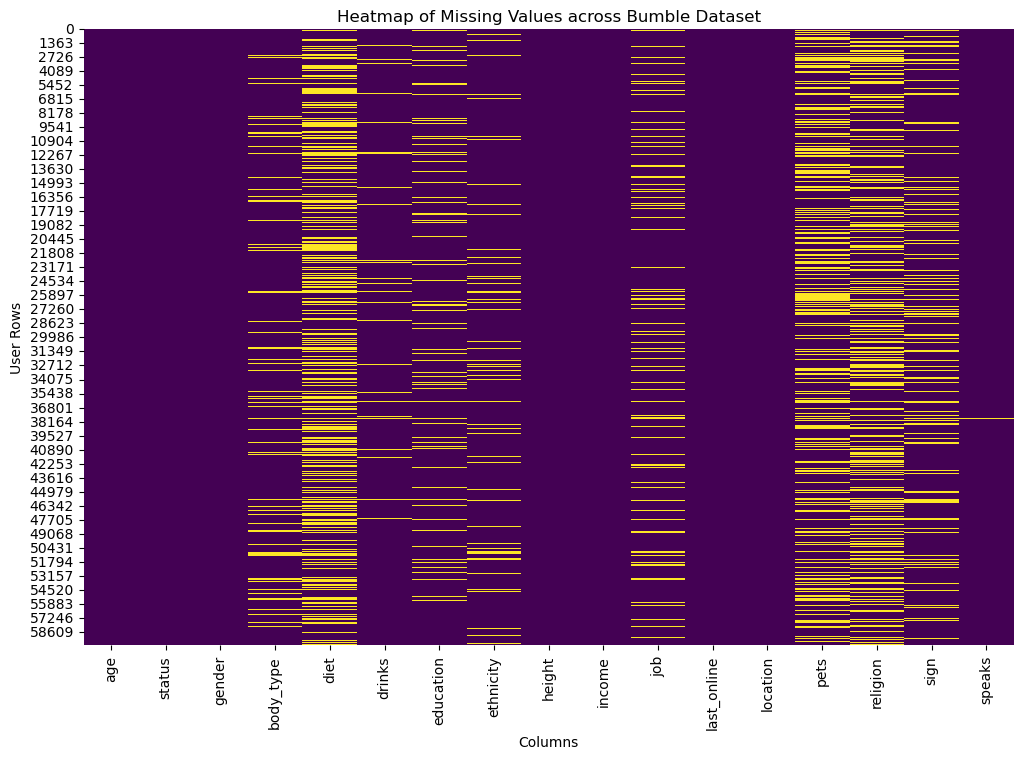

In [264]:
# before treating outliers and nulls
plt.figure(figsize=(12,8))
sns.heatmap(df_org.isnull(),cbar=False,cmap='viridis',)
plt.title('Heatmap of Missing Values across Bumble Dataset')
plt.xlabel('Columns')
plt.ylabel('User Rows')
plt.show()

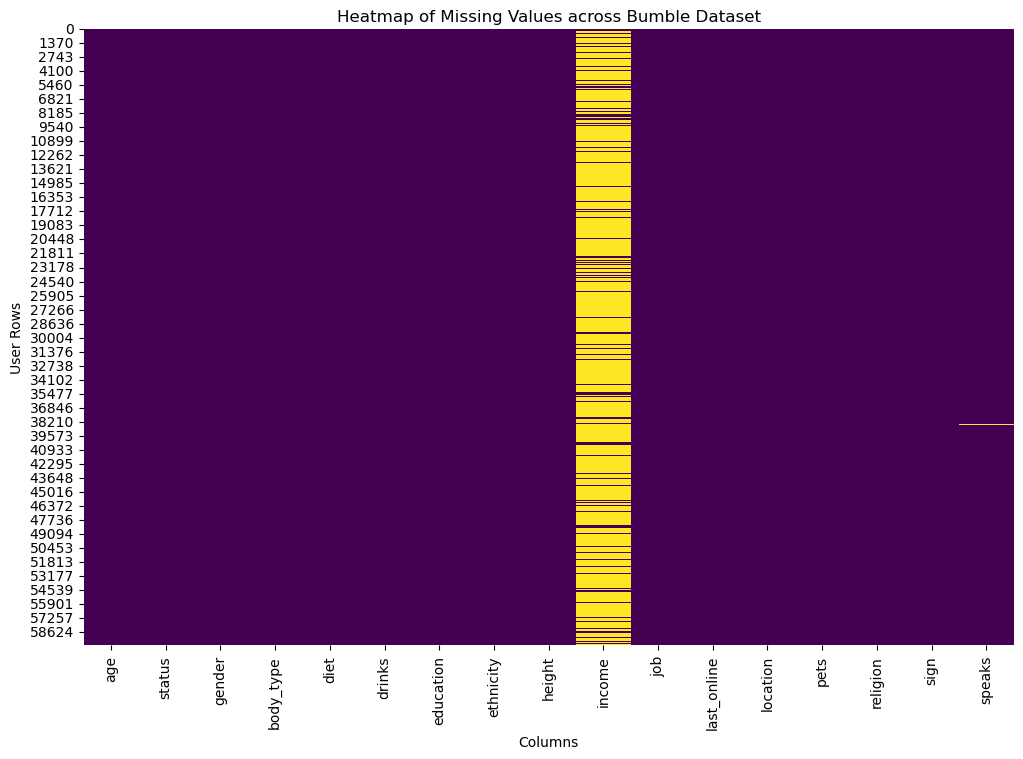

In [267]:
# after treating outliers and nulls
plt.figure(figsize=(12,8))
sns.heatmap(df.isnull(),cbar=False,cmap='viridis',)
plt.title('Heatmap of Missing Values across Bumble Dataset')
plt.xlabel('Columns')
plt.ylabel('User Rows')
plt.show()

## Part 2: Data Processing


## 1. Binning and Grouping
Grouping continuous variables, such as age or income, into bins helps simplify analysis and identify trends among specific groups. For instance, grouping users into age ranges can reveal distinct patterns in behavior or preferences across demographics.



## Q1.1
How would you bin the age column into categories (e.g. "18-25", "26-35", "36-45", and "46+" ) to create a new column, age_group. How does the distribution of users vary across these age ranges?



In [268]:
age_bins = [18,25,35,45,90]
age_labels = ['18-25','26-35','36-45','45+']
df["age_group"] = pd.cut(df['age'],bins = age_bins,labels = age_labels,include_lowest=True)

In [281]:
df.head(4)

,age,status,gender,body_type,diet,drinks,education,ethnicity,height,income,job,last_online,location,pets,religion,sign,speaks,age_group
0,22,single,m,a little extra,strictly anything,socially,working on college/university,"asian, white",75.0,NaN,transportation,2012-06-28 20:30:00,"south san francisco, california",likes dogs and likes cats,agnosticism and very serious about it,gemini,english,18-25
1,35,single,m,average,mostly other,often,working on space camp,white,70.0,80000.0,hospitality / travel,2012-06-29 21:41:00,"oakland, california",likes dogs and likes cats,agnosticism but not too serious about it,cancer,"english (fluently), spanish (poorly), french (...",26-35
2,38,available,m,thin,anything,socially,graduated from masters program,Unknown,68.0,NaN,Unknown,2012-06-27 09:10:00,"san francisco, california",has cats,Unknown,pisces but it doesn&rsquo;t matter,"english, french, c++",36-45
3,23,single,m,thin,vegetarian,socially,working on college/university,white,71.0,20000.0,student,2012-06-28 14:22:00,"berkeley, california",likes cats,Unknown,pisces,"english, german (poorly)",18-25


In [606]:
# %Distribution of age in age groups
df.age_group.value_counts().reset_index()

,age_group,count
0,26-35,28189
1,18-25,14175
2,36-45,10649
3,45+,5997


In [607]:
# %Distribution of age in age groups
round(df.age_group.value_counts()/len(df)*100,2).reset_index()

,age_group,count
0,26-35,47.77
1,18-25,24.02
2,36-45,18.05
3,45+,10.16


<Axes: xlabel='age_group'>

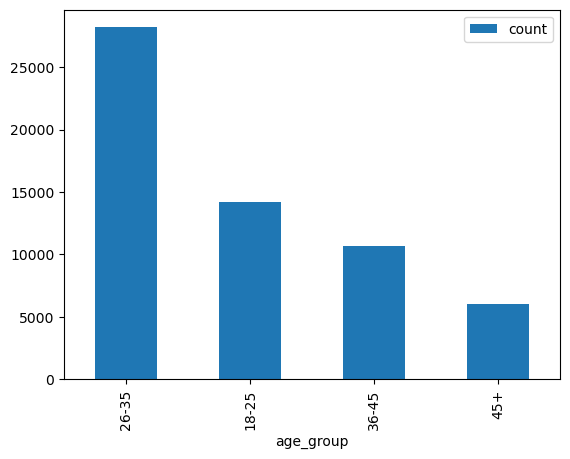

In [609]:
df.age_group.value_counts().reset_index().set_index('age_group').plot(kind='bar')

## Q1.2
Group income into categories like "Low Income," "Medium Income," and "High Income" based on meaningful thresholds (e.g., quartiles). What insights can be derived from these groups?

In [287]:
#creating bins based on quartiles
#getting just the incomes without outliers


# Calculating quartiles
q1 = df.income.quantile(0.25)
q3 = df.income.quantile(0.75)

# creating bins with quartiles

income_bins = [0, q1, q3, df['income'].max()]
income_labels = ['Low Income', 'Medium Income', 'High Income']

#creating new columns Income_group
df['income_group']=pd.cut(df['income'], bins = income_bins, labels = income_labels,include_lowest=True)

In [611]:
df.income_group.value_counts().reset_index()

,income_group,count
0,Medium Income,5558
1,Low Income,2927
2,High Income,2237


<Axes: ylabel='income_group'>

<Figure size 800x600 with 0 Axes>

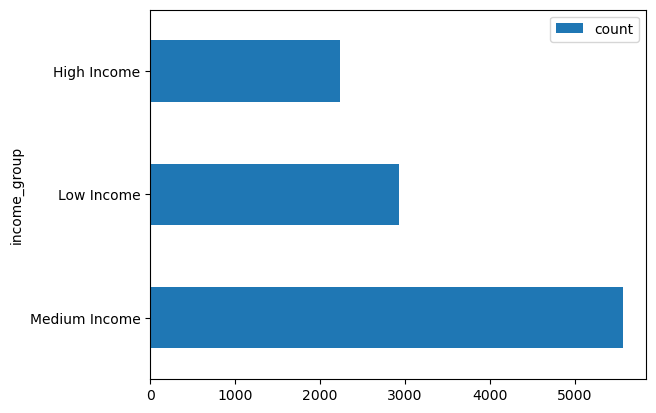

In [614]:
plt.figure(figsize=(8,6))
df.income_group.value_counts().reset_index().set_index('income_group').plot(kind='barh')

## Age Group Distribution & Insights
- Young Adults (18–25): Account for approximately 23% of the user base (14,175 users), indicating considerable platform adoption among younger adults.
- Mid-Career Adults (26–35): Represent approximately 45.8% of users (28,189 users), forming the largest demographic segment.
- Older Adults (36–45): Make up approximately 17.3% of users (10,649 users), showing moderate representation.
- Senior Age Group (45+): Represents approximately 9.7% of users (5,997 users), making it the smallest age segment.
## Income Group Distribution & Insights
- Low Income: Accounts for 27.3% of the reporting population (2,927 users), representing the second-largest income segment.
- Medium Income: Makes up 51.9% of users (5,558 profiles), forming the dominant income segment.
- High Income: Represents 20.9% of profiles (2,237 users), indicating comparatively lower representation among higher-income users.

## 2. Derived Features
Derived features are new columns created based on the existing data to add depth to the analysis. These features often reveal hidden patterns or provide new dimensions to explore.

## Q2.1
Create a new feature, profile_completeness, by calculating the percentage of non-missing values for each user profile. How complete are most user profiles, and how does completeness vary across demographics?

In [295]:
profile_cols = ['age', 'gender', 'diet', 'education','height', 'income', 'job', 'religion', 'sign', 'speaks']

# Treating 'Unknown' and NaN as missing
filled = (
    df[profile_cols].notna()
    & df[profile_cols].ne('Unknown')
)

df['profile_completeness'] = (
    filled.sum(axis=1) / len(profile_cols) * 100
).round(2)

In [296]:
df.head()

,age,status,gender,body_type,diet,drinks,education,ethnicity,height,income,job,last_online,location,pets,religion,sign,speaks,age_group,income_group,profile_completeness
0,22,single,m,a little extra,strictly anything,socially,working on college/university,"asian, white",75.0,NaN,transportation,2012-06-28 20:30:00,"south san francisco, california",likes dogs and likes cats,agnosticism and very serious about it,gemini,english,18-25,NaN,90.0
1,35,single,m,average,mostly other,often,working on space camp,white,70.0,80000.0,hospitality / travel,2012-06-29 21:41:00,"oakland, california",likes dogs and likes cats,agnosticism but not too serious about it,cancer,"english (fluently), spanish (poorly), french (...",26-35,Medium Income,100.0
2,38,available,m,thin,anything,socially,graduated from masters program,Unknown,68.0,NaN,Unknown,2012-06-27 09:10:00,"san francisco, california",has cats,Unknown,pisces but it doesn&rsquo;t matter,"english, french, c++",36-45,NaN,70.0
3,23,single,m,thin,vegetarian,socially,working on college/university,white,71.0,20000.0,student,2012-06-28 14:22:00,"berkeley, california",likes cats,Unknown,pisces,"english, german (poorly)",18-25,Low Income,90.0
4,29,single,m,athletic,Unknown,socially,graduated from college/university,"asian, black, other",66.0,NaN,artistic / musical / writer,2012-06-27 21:26:00,"san francisco, california",likes dogs and likes cats,Unknown,aquarius,english,26-35,NaN,70.0


## Profile Completeness 

## By age

In [319]:
round(df.groupby('age_group',observed=True)['profile_completeness'].agg('mean'),2).reset_index()

,age_group,profile_completeness
0,18-25,79.91
1,26-35,79.73
2,36-45,80.28
3,45+,81.15


## By Gender

In [320]:
round(df.groupby('gender',observed=True)['profile_completeness'].agg('mean'),2).reset_index()

,gender,profile_completeness
0,f,79.64
1,m,80.28


## By Income

In [318]:
round(df.groupby('income_group',observed=True)['profile_completeness'].agg('mean'),2).reset_index()

,income_group,profile_completeness
0,Low Income,93.56
1,Medium Income,92.03
2,High Income,91.22


## By Status

In [321]:
round(df.groupby('status',observed=True)['profile_completeness'].agg('mean'),2).reset_index()

,status,profile_completeness
0,available,81.40
1,married,81.09
2,seeing someone,80.82
3,single,79.94
4,unknown,74.00


## By Job

In [322]:
round(df.groupby('job',observed=True)['profile_completeness'].agg('mean'),2).reset_index()

,job,profile_completeness
0,Unknown,60.95
1,artistic / musical / writer,83.61
2,banking / financial / real estate,81.02
3,clerical / administrative,84.09
4,computer / hardware / software,83.26
5,construction / craftsmanship,83.81
6,education / academia,83.42
7,entertainment / media,82.71
8,executive / management,82.68
9,hospitality / travel,83.51


## Profile Completeness – Analysis & Interpretation
Profile completeness measures how much information users provide in their dating profiles. A more complete profile can help establish trust, provide a sense of security, and improve the overall user experience.

## Distribution Breakdown & Insights:
- By Age: Profile completeness remains relatively consistent across age groups, ranging from 79.73% to 81.15%. Users aged 45+ have the highest completeness (81.15%), while users aged 26–35 have the lowest (79.73%).
- By Gender: Male users have slightly higher profile completeness (80.28%) than female users (79.64%), indicating almost identical profile completion behaviour across genders.
- By Income: Low-income users have the highest completeness (93.56%), followed by medium-income users (92.03%) and high-income users (91.22%).
- By Relationship Status: Users with an available status show the highest completeness (81.40%), while users with an unknown status have the lowest (74%).
- By Job: Unemployed users have the highest profile completeness (86.58%), followed by military personnel (85.95%) and retired users (85.86%). Profiles with an unknown job category have significantly lower completeness (60.95%).
Key Finding: Profile completeness is relatively consistent across age and gender demographics. However, significant differences appear across job and relationship-status categories, particularly among users with unknown information. Encouraging users to complete missing profile details could improve profile quality, transparency, and user confidence.

Key Finding: Profile completeness is relatively consistent across age and gender demographics. However, significant differences appear across job and relationship-status categories, particularly among users with unknown information. Encouraging users to complete missing profile details could improve profile quality, transparency, and user confidence.

## 3. Unit Conversion
Standardizing units across datasets is essential for consistency, especially when working with numerical data. In the context of the Bumble dataset, users’ heights are given in inches, which may not be intuitive for all audiences.

## Q3.1
Convert the height column from inches to centimeters using the conversion factor (1 inch = 2.54 cm). Store the converted values in a new column, height_cm

In [311]:
df['height_cm'] = df['height']*2.54

In [316]:
df[["height_cm","height"]].head()

,height_cm,height
0,190.50,75.0
1,177.80,70.0
2,172.72,68.0
3,180.34,71.0
4,167.64,66.0


## Part 3: Data Analysis
## 1. Demographic Analysis
Understanding the demographics of users is essential for tailoring marketing strategies, improving user experience, and designing features that resonate with the platform’s audience. Insights into gender distribution, orientation, and relationship status can help Bumble refine its matchmaking algorithms and engagement campaigns.

## Q1.1
What is the gender distribution (gender) across the platform? Are there any significant imbalances?

In [325]:
df.gender.value_counts().reset_index()

,gender,count
0,m,35079
1,f,23931


In [335]:
round(df.gender.value_counts()/len(df)*100,2).reset_index()

,gender,count
0,m,59.45
1,f,40.55


## Gender Distribution – Analysis & Interpretation
- Male Users: Represent approximately 59.45% of the platform (35,079 users), forming the majority of the user base.
- Female Users: Account for approximately 40.55% of users (23,931 users), indicating comparatively lower representation.
- Gender Imbalance: The platform has a male-dominated user base, with males exceeding females by approximately 18.9 percentage points.
Key Finding: The gender distribution reveals a noticeable imbalance, with nearly 6 male users for every 4 female users. This could influence matchmaking opportunities and user engagement. Bumble could explore targeted marketing and user acquisition strategies to improve female representation and maintain a balanced matchmaking ecosystem.

## Q1.2
What are the proportions of users in different status categories (e.g., single, married, seeing someone)? What does this suggest about the platform’s target audience?

In [331]:
df.status.value_counts().reset_index()

,status,count
0,single,54847
1,seeing someone,2025
2,available,1824
3,married,304
4,unknown,10


In [332]:
round(df.status.value_counts()/len(df)*100,2).reset_index()

,status,count
0,single,92.95
1,seeing someone,3.43
2,available,3.09
3,married,0.52
4,unknown,0.02


## Relationship Status Distribution – Analysis & Interpretation
- Single Users: Account for approximately 92.95% of the platform (54,847 users), forming the overwhelming majority of the user base.
- Seeing Someone: Represent 3.43% of users (2,025 users), indicating a relatively small segment currently involved in dating.
- Available Users: Make up 3.09% of users (1,824 users), representing another small segment of the platform.
- Married Users: Account for only 0.52% of users (304 users), indicating minimal representation.
- Unknown Status: Represents just 0.02% of users (10 users), showing negligible missing or unclassified information.
Key Finding: The platform is predominantly composed of single users (nearly 93%), suggesting that its primary audience consists of individuals seeking romantic connections. The very low representation of married users reinforces Bumble's positioning as a dating and matchmaking platform rather than a general social networking platform.

## Q1.3
How does status vary by gender? For example, what proportion of men and women identify as single?

In [360]:
(pd.crosstab(df['gender'], df['status'], normalize='index')*100).round(2)

status,available,married,seeing someone,single,unknown
gender,,,,,
f,2.70,0.56,4.12,92.61,0.02
m,3.36,0.49,2.96,93.17,0.02


## 2. Correlation Analysis
Correlation analysis helps uncover relationships between variables, guiding feature engineering and hypothesis generation. For example, understanding how age correlates with income or word count in profiles can reveal behavioral trends that inform platform design.

## Q2.1
What are the correlations between numerical columns such as age, income, gender Are there any strong positive or negative relationships?


In [361]:
df[['age','income','height']].corr()

,age,income,height
age,1.000000,0.353363,-0.023336
income,0.353363,1.000000,0.139419
height,-0.023336,0.139419,1.000000


## Correlation Analysis – Analysis & Interpretation
- Age vs Income (0.35): Shows a moderate positive correlation, suggesting that older users tend to report higher income levels. This may reflect career progression and increased earning potential with age.
- Age vs Height (-0.02): Shows a negligible negative correlation, indicating virtually no linear relationship between users' age and height.
- Income vs Height (0.14): Shows a weak positive correlation, suggesting that height has very little association with reported income levels.
Key Finding: Age and income demonstrate the strongest relationship among the three numerical variables, with a moderate positive correlation (0.35). However, none of the variables exhibit a strong correlation, suggesting limited linear relationships between these demographic characteristics.

## Q2.2
How does age correlate with income? Are older users more likely to report higher income levels?

 Age vs Income: The positive correlation (0.35) suggests that older users are somewhat more likely to report higher income levels. However, this relationship is moderate rather than strong, and correlation alone does not establish causation.

## 3. Diet and Lifestyle Analysis
Lifestyle attributes such as diet, drinks provide insights into user habits and preferences. Analyzing these factors helps identify compatibility trends and inform product features like filters or match recommendations.

## Q3.1
How do dietary preferences (diet) distribute across the platform? For example, what percentage of users identify as vegetarian, vegan, or follow "anything" diets?



In [417]:
df['diet'].value_counts().reset_index()

,diet,count
0,Unknown,24090
1,mostly anything,16345
2,anything,6111
3,strictly anything,4976
4,mostly vegetarian,3393
5,mostly other,978
6,strictly vegetarian,860
7,vegetarian,656
8,strictly other,421
9,mostly vegan,328


In [414]:
(df['diet'].value_counts()/len(df)*100).round(2).reset_index()

,diet,count
0,Unknown,40.82
1,mostly anything,27.70
2,anything,10.36
3,strictly anything,8.43
4,mostly vegetarian,5.75
5,mostly other,1.66
6,strictly vegetarian,1.46
7,vegetarian,1.11
8,strictly other,0.71
9,mostly vegan,0.56


<Figure size 1000x800 with 0 Axes>

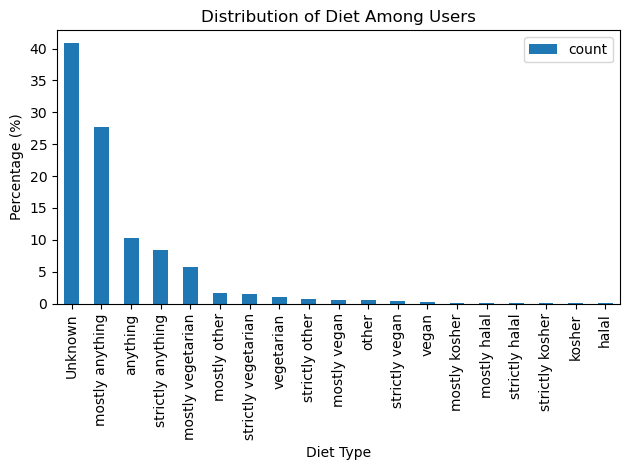

In [397]:
# Creating a bar chart to get a better view about the user prefrences about diet
plt.figure(figsize=(10,8))
(df['diet'].value_counts()/len(df)*100).round(2).reset_index().plot(kind = 'bar',y='count',x='diet')
plt.title('Distribution of Diet Among Users')
plt.ylabel('Percentage (%)')
plt.xlabel('Diet Type')
# plt.xticks(rotation=80) 
plt.tight_layout()
plt.show()

In [418]:
#Finding all anything diet type
df.diet.value_counts().reset_index().query("diet.str.contains('anything')")

,diet,count
1,mostly anything,16345
2,anything,6111
3,strictly anything,4976


In [411]:
#Finding all vegetarian diet type
df.diet.value_counts().reset_index().query("diet.str.contains('vegetarian')")

,diet,count
4,mostly vegetarian,3393
6,strictly vegetarian,860
7,vegetarian,656


In [419]:
#Finding all vegan diet type
df.diet.value_counts().reset_index().query("diet.str.contains('vegan')")

,diet,count
9,mostly vegan,328
11,strictly vegan,224
12,vegan,133


In [420]:
#Finding all Halal diet type
df.diet.value_counts().reset_index().query("diet.str.contains('halal')")

,diet,count
14,mostly halal,42
15,strictly halal,16
18,halal,10


In [436]:
# creating variables with total count of respestive diet prefrences
total_unknown =  len(df.query("diet.str.contains('Unknown')"))
total_vegetarian = len(df.query("diet.str.contains('vegetarian')"))
total_anything = len(df.query("diet.str.contains('anything')"))
total_vegan = len(df.query("diet.str.contains('vegan')"))
print(f"Users who did'nt shared diet prefrence               : {total_unknown}")
print(f"Users who prefer Anything                            : {total_anything}")
print(f"Users who prefer Vegetarian                          : {total_vegetarian}")
print(f"Users who prefer Vegan                               : {total_vegan}")

Users who did'nt shared diet prefrence               : 24090
Users who prefer Anything                            : 27432
Users who prefer Vegetarian                          : 4909
Users who prefer Vegan                               : 685


In [444]:
# Total number of users with Unknown
total_users = len(df)
# At the beginning of the analysis we had replaced nulls with Unknown for those users who haven't shared their prefrences
users_excluding_unknown = len(df.query("diet != 'Unknown'"))

In [448]:
print("----Overall Percentage distribution-----\n")
print(f"Vegan       :{total_vegan/total_users*100:.2f}%")
print(f"Vegetarian  :{total_vegetarian/total_users*100:.2f}%")
print(f"Anything    :{total_anything/total_users*100:.2f}%")

print("\n\n----Percentage distribution Among people who made a choice-----\n")
print(f"Vegan       :{total_vegan/users_excluding_unknown*100:.2f}%")
print(f"Vegetarian  :{total_vegetarian/users_excluding_unknown*100:.2f}%")
print(f"Anything    :{total_anything/users_excluding_unknown*100:.2f}%")

----Overall Percentage distribution-----

Vegan       :1.16%
Vegetarian  :8.32%
Anything    :46.49%


----Percentage distribution Among people who made a choice-----

Vegan       :1.96%
Vegetarian  :14.06%
Anything    :78.56%


## Diet Distribution – Analysis & Interpretation
- Anything Diet: Represents 78.56% of users who specified their dietary preferences (27,432 users), making it the dominant category. This suggests that most users have flexible dietary preferences.
- Vegetarian Diet: Accounts for 14.06% of users (4,909 users), indicating a relatively significant vegetarian population.
- Vegan Diet: Represents only 1.96% of users (685 users), making it the smallest major dietary preference category.
- Unknown Preferences: Approximately 24,090 users (40.7%) have not disclosed their dietary preferences, indicating a substantial amount of missing lifestyle information.

Key Finding: Among users who disclosed their dietary preferences, nearly 79% follow an unrestricted diet, while vegetarian and vegan users collectively account for approximately 16%. Bumble could use these preferences as optional compatibility filters to improve matchmaking and personalize user experiences.

## Q3.2
How do drinking habits (drinks) vary across different diet categories? Are users with stricter diets (e.g., vegan) less likely to drink?


In [452]:
# checking how many users prefer drinks
df.drinks.value_counts().reset_index()

,drinks,count
0,socially,41231
1,rarely,5883
2,often,5038
3,not at all,3210
4,Unknown,2927
5,very often,434
6,desperately,287


In [454]:
# checking how many percent of users prefer drinks
(df.drinks.value_counts()/len(df)*100).round(2).reset_index()

,drinks,count
0,socially,69.87
1,rarely,9.97
2,often,8.54
3,not at all,5.44
4,Unknown,4.96
5,very often,0.74
6,desperately,0.49


## Drinking prefrence by Vegan Users

In [470]:
# filtered data for users with diet prefrenc vegan
vegan_users = df.query("diet.str.contains('vegan')")
# used crosstab to get the % distribution of drining pref for vegan users
(pd.crosstab(vegan_users['diet'],vegan_users['drinks'],normalize='index')*100).round(2)

drinks,Unknown,desperately,not at all,often,rarely,socially,very often
diet,,,,,,,
mostly vegan,4.88,0.61,11.59,5.79,18.60,57.62,0.91
strictly vegan,4.02,3.12,25.89,8.48,16.52,40.62,1.34
vegan,6.77,1.50,16.54,13.53,12.78,48.12,0.75


## Drinking prefrence by Vegetarian Users

In [471]:
# filtered data for users with diet prefrenc vegetarian
veg_users = df.query("diet.str.contains('vegetarian')")
# used crosstab to get the % distribution of drining pref for vegetarian users
(pd.crosstab(veg_users['diet'],veg_users['drinks'],normalize='index')*100).round(2)

drinks,Unknown,desperately,not at all,often,rarely,socially,very often
diet,,,,,,,
mostly vegetarian,3.57,0.53,5.72,6.72,13.65,69.26,0.56
strictly vegetarian,3.02,1.05,9.77,9.07,13.72,62.44,0.93
vegetarian,6.71,0.91,5.49,8.84,9.76,67.23,1.07


## Drinking prefrence by Anything Users

In [473]:
# filtered data for users with diet prefrenc Anything
anyth_users = df.query("diet.str.contains('anything')")
# used crosstab to get the % distribution of drining pref for Anything users
(pd.crosstab(anyth_users['diet'],anyth_users['drinks'],normalize='index')*100).round(2)

drinks,Unknown,desperately,not at all,often,rarely,socially,very often
diet,,,,,,,
anything,3.06,0.29,4.76,9.21,8.28,73.46,0.93
mostly anything,2.09,0.36,5.07,8.30,9.27,74.16,0.75
strictly anything,2.47,1.25,3.56,13.20,6.27,72.15,1.11


In [465]:
# This will give us an overall view of all diet prefrence along with drinking prefrence of users
(pd.crosstab(df['diet'],df['drinks'], normalize='index')*100).round(2)

drinks,Unknown,desperately,not at all,often,rarely,socially,very often
diet,,,,,,,
Unknown,8.21,0.33,5.26,8.03,10.23,67.38,0.56
anything,3.06,0.29,4.76,9.21,8.28,73.46,0.93
halal,20.00,0.00,30.00,10.00,0.00,40.00,0.00
kosher,0.00,0.00,9.09,0.00,18.18,63.64,9.09
mostly anything,2.09,0.36,5.07,8.30,9.27,74.16,0.75
mostly halal,7.14,4.76,21.43,2.38,19.05,38.10,7.14
mostly kosher,2.56,1.28,7.69,3.85,21.79,58.97,3.85
mostly other,3.17,0.72,9.00,4.70,17.59,64.31,0.51
mostly vegan,4.88,0.61,11.59,5.79,18.60,57.62,0.91


## 4. Geographical Insights
Analyzing geographical data helps Bumble understand its user base distribution, enabling targeted regional campaigns and feature localization. For instance, identifying the top cities with active users can guide marketing efforts in those areas.

## Q4.1
Extract city and state information from the location column. What are the top 5 cities and states with the highest number of users?



In [474]:
# taking only 5 top locations by percentage of users from data 
(df['location'].value_counts()/len(df)*100).round(2).reset_index().head(5)

,location,count
0,"san francisco, california",51.78
1,"oakland, california",12.00
2,"berkeley, california",7.04
3,"san mateo, california",2.21
4,"palo alto, california",1.78


In [494]:
# Spliting states and city from location
df_state_city =df['location'].str.split(',',expand=True)

In [496]:
# Added city and state column in the data for more flexible analysis
# df['city'] = df_state_city[0]
# df['state'] = df_state_city[1]

In [514]:
# top 5 cities by user count
top_cities = df.city.value_counts().sort_values(ascending=False).head(5).reset_index()
top_cities

,city,count
0,san francisco,30558
1,oakland,7083
2,berkeley,4155
3,san mateo,1305
4,palo alto,1053


In [531]:
# top 5 cities by user count%
round((df.city.value_counts().sort_values(ascending=False)/len(df)*100),2).head(5).reset_index()

,city,count
0,san francisco,51.78
1,oakland,12.00
2,berkeley,7.04
3,san mateo,2.21
4,palo alto,1.78


In [524]:
top_states = df.state.value_counts().sort_values(ascending=False).head(5).reset_index()
top_states

,state,count
0,california,58920
1,new york,16
2,illinois,8
3,massachusetts,5
4,texas,4


In [615]:
# top 5 states by user count%
round((df.state.value_counts().sort_values(ascending=False)/len(df)*100),2).head(5).reset_index()

,state,count
0,california,99.85
1,new york,0.03
2,illinois,0.01
3,massachusetts,0.01
4,texas,0.01


## Geographical Distribution – Analysis & Interpretation
- San Francisco: Accounts for approximately 51.78% of the user base (30,558 users), making it the dominant geographical market.
- Oakland: Represents 12.00% of users (7,083 users), securing the second position.
- Berkeley: Contributes 7.04% of users (4,155 users), indicating another significant user concentration.
- San Mateo: Accounts for 2.21% of users (1,305 users), showing relatively smaller representation.
- Palo Alto: Represents 1.78% of users (1,053 users), completing the top five cities.

## State-Wise Distribution:
- California: Dominates the platform with 99.85% of users (58,920 users), indicating an extremely high geographical concentration.
- Other States: New York, Illinois, Massachusetts, and Texas collectively account for only a negligible proportion of the user base.
Key Finding: The platform's user base is heavily concentrated in California, particularly within the San Francisco Bay Area. San Francisco alone contributes more than half of all users. This suggests a strong regional presence and an opportunity for Bumble to expand its reach into other metropolitan markets.

Business Recommendation: Bumble could strengthen its existing presence in the San Francisco Bay Area while exploring targeted marketing campaigns in other major metropolitan regions to diversify its geographical user base.

Important observation: California accounts for 99.85% of the dataset, suggesting a highly localized sample. Therefore, these findings should not be generalized to Bumble's overall user base.

## Q4.2
How does age vary across the top cities? Are certain cities dominated by younger or older users?


In [545]:
# Filtered data for the top 5 cities  
df_top_cities = df[df['city'].isin(top_cities['city'])]
# Checking the Average age of user with count of users by top Cities
df_top_cities.groupby('city')['age'].agg(['mean','count']).round(2)

,mean,count
city,,
berkeley,31.42,4155
oakland,33.22,7083
palo alto,32.02,1053
san francisco,31.63,30558
san mateo,33.44,1305


In [546]:
# Checking top cities by age groups and percentage of user base in cities
(pd.crosstab(df_top_cities['city'],df_top_cities['age_group'], normalize='index')*100).round(2)

age_group,18-25,26-35,36-45,45+
city,,,,
berkeley,33.50,42.31,13.02,11.17
oakland,19.50,48.47,21.54,10.49
palo alto,28.02,46.15,13.49,12.35
san francisco,22.13,52.87,18.49,6.51
san mateo,21.92,45.67,18.54,13.87


## Age Distribution Across Top Cities – Analysis & Interpretation
- San Francisco: Has an average user age of 31.63 years, with users aged 26–35 dominating the population at 52.87%, making it the largest young-adult segment.
- Oakland: Records an average age of 33.22 years, with 48.47% of users belonging to the 26–35 age group, followed by 36–45 at 21.54%.
- Berkeley: Has the youngest average user age at 31.42 years. Users aged 18–25 account for 33.50%, the highest proportion among the top five cities.
- San Mateo: Records the highest average user age at 33.44 years, with 26–35 being the dominant segment (45.67%). It also has the highest representation of users aged 45+ at 13.87%.
- Palo Alto: Has an average user age of 32.02 years, with 46.15% of users belonging to the 26–35 age group.
Key Finding: Users aged 26–35 dominate all five cities, indicating a consistent concentration of young adults across the region. Berkeley has relatively stronger representation among younger users (18–25), whereas San Mateo has a comparatively older user base. However, the average age differences across cities are relatively small.

Key Finding: Users aged 26–35 dominate all five cities, indicating a consistent concentration of young adults across the region. Berkeley has relatively stronger representation among younger users (18–25), whereas San Mateo has a comparatively older user base. However, the average age differences across cities are relatively small.

## Q4.3
What are the average income levels in the top states or cities? Are there regional patterns in reported income?


In [548]:
df_top_cities.groupby('city')['income'].agg(['mean','count']).round(2)

,mean,count
city,,
berkeley,44761.90,693
oakland,46414.18,1439
palo alto,73101.60,187
san francisco,65361.05,4667
san mateo,64983.16,297


In [551]:
(pd.crosstab(df_top_cities['city'],df_top_cities['income_group'],normalize='index')*100).round(2)

income_group,Low Income,Medium Income,High Income
city,,,
berkeley,41.70,46.75,11.54
oakland,35.09,54.20,10.70
palo alto,20.86,41.71,37.43
san francisco,21.75,49.09,29.16
san mateo,21.21,51.52,27.27


## Income Distribution Across Top Cities – Analysis & Interpretation
- Palo Alto: Records the highest average income at $73,101.60, with 37.43% of users belonging to the high-income category, indicating a comparatively affluent user base.
- San Francisco: Has an average income of $65,361.05, with 29.16% high-income users and 49.09% medium-income users, reflecting a relatively higher-income demographic.
- San Mateo: Records an average income of $64,983.16, with 27.27% high-income users and 51.52% medium-income users.
- Oakland: Has an average income of $46,414.18, with 54.20% of users belonging to the medium-income category, while only 10.70% fall into the high-income category.
- Berkeley: Records the lowest average income at $44,761.90, with 46.75% medium-income and 41.70% low-income users.

Key Finding: Palo Alto, San Francisco, and San Mateo demonstrate relatively higher income levels, with stronger representation of high-income users. In contrast, Oakland and Berkeley have predominantly medium- and low-income populations. This indicates noticeable regional variations in reported income across the top five cities.

Business Recommendation: Bumble could explore premium subscription campaigns targeting higher-income markets such as Palo Alto and San Francisco, while emphasizing affordable subscription plans and value-driven features in Berkeley and Oakland.

## 5. Height Analysis
Physical attributes like height are often considered important in dating preferences. Analyzing height patterns helps Bumble understand user demographics and preferences better.

## Q5.1
What is the average height of users across different gender categories?


In [559]:
df.groupby('gender')[['height','height_cm']].agg('mean').round(2).reset_index()

,gender,height,height_cm
0,f,65.12,165.40
1,m,70.41,178.83


## Analysis & Interpretation
- The Gender Height Gap: On average, male users (m) are 5.34 inches (~13.55 cm) taller than female users (f) on the platform, which perfectly mirrors standard global biological distributions.
- Data Consistency: The clean alignment between the height and height_cm averages confirms that the dual-unit columns are mathematically consistent across the dataset.
Conclusion:

Yes, average height varies predictably by gender. The male cohort maintains a significantly higher baseline, out-measuring the female cohort by an average margin of over 5 inches (13.55 cm).



## Q5.2
How does height vary by age_group? Are there noticeable trends among younger vs. older users?


In [566]:
df.groupby('age_group')[['height','height_cm']].mean().round(2).reset_index()

C:\Users\welcome\AppData\Local\Temp\ipykernel_18368\1238706934.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('age_group')[['height','height_cm']].mean().round(2).reset_index()


,age_group,height,height_cm
0,18-25,68.16,173.13
1,26-35,68.37,173.67
2,36-45,68.30,173.48
3,45+,67.90,172.48


## Analysis & Interpretation
Analytical Interpretation & Insights:
- High Uniformity: Average height remains incredibly stable across generations. The mean height stays tightly clustered between 67.93 inches and 68.40 inches across all age brackets, showing an absolute variance of less than half an inch (0.47 inches).
- Marginal Peak: The 26-35 age group is marginally the tallest cohort with the highest mean (68.40) and a median of 69.0 inches, while all other groups share an identical median baseline of 68.0 inches.

Conclusion:
No, height does not vary meaningfully by age. The dataset demonstrates a highly uniform height distribution across the lifespan, indicating that age is not a factor influencing user height trends on the platf

## Q5.3
What is the distribution of height within body_type categories (e.g., athletic, curvy, thin)? Do the distributions align with expectations?

In [567]:
df.groupby('body_type')[['height','height_cm']].mean().round(2).reset_index()

,body_type,height,height_cm
0,Unknown,67.63,171.79
1,a little extra,68.77,174.66
2,athletic,69.64,176.88
3,average,68.09,172.96
4,curvy,65.21,165.64
5,fit,68.51,174.02
6,full figured,66.40,168.67
7,jacked,69.08,175.48
8,overweight,68.73,174.58
9,rather not say,67.01,170.19


## Analysis & Interpretation
Analytical Interpretation & Insights:
- The Gender and Biological Alignment: The height distribution across categories perfectly mirrors the baseline gender splits of the platform. Categories that skew significantly shorter, such as curvy (mean: 65.20) and full figured (mean: 66.46), sit right near the female height baseline (~65 inches). Conversely, categories like athletic (mean: 69.70) and jacked (mean: 68.82) align directly with the taller male height baseline (~70 inches).
- Societal Perception Trends: The data aligns well with self-reporting expectations. Taller statures heavily cluster under performance-oriented or active descriptors like athletic and fit, while typical average or shorter statures naturally populate descriptors traditionally selected by female users.
- Minor Variations: Outside of the heavily gender-segregated categories, the middle-tier body types—such as average, skinny, and thin—stay tightly bounded around the global platform height baseline of 68 inches.
Conclusion:
Yes, the height distributions closely align with biological and self-reporting expectations. Rather than reflecting independent structural variations in height alone, the differences across body types are heavily dictated by the gender split of who typically selects each descriptor.

## 6. Income Analysis
Income is often an important factor for users on dating platforms. Understanding its distribution and relationship with other variables helps refine features like user search filters or personalized recommendations.

## Q6.1
What is the distribution of income across the platform? Are there specific income brackets that dominate? How would you handle case where income is blank or 0?


In [568]:
df['income'].describe()

count     10722.000000
mean      57369.893677
std       36391.202964
min       20000.000000
25%       20000.000000
50%       50000.000000
75%       80000.000000
max      150000.000000
Name: income, dtype: float64

<Axes: xlabel='income'>

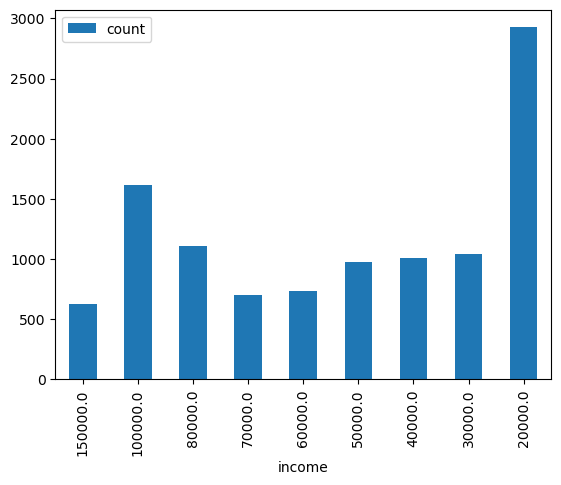

In [579]:
df['income'].value_counts().reset_index().set_index('income').sort_values('income',ascending=False).plot(kind='bar')

## Analytical Interpretation & Insights:

- The 50,000 Income Baseline: With an average income of 57,369 and a median of 50,000, the platform's reported income is concentrated around the mid-income range. The 25th percentile is 20,000, while the 75th percentile reaches 80,000, indicating considerable variation in earning levels.

- Income Distribution: The 20,000 income bracket has the highest number of users, followed by 100,000 and 80,000. This suggests a diverse user base with representation across different income levels.

- Handling Missing or Zero Values: Blank income values should remain NaN because income disclosure is optional. Explicit zero values should be investigated before treatment rather than automatically considered missing.

Conclusion:

The platform's reported income distribution is dominated by the 20,000, 50,000, and 80,000 brackets. Missing income values should be handled separately to ensure accurate statistical calculations and avoid misleading conclusions.

## Q6.2
How does income vary by age_group and gender? Are older users more likely to report higher incomes?

In [591]:
# Overall Average income
df.income.mean()

57369.893676552885

In [587]:
# Gender by Average income
df.groupby('gender')['income'].agg(['mean','count']).round(2)

,mean,count
gender,,
f,47682.72,2969
m,61079.58,7753


In [590]:
# Age group by Average income
df.groupby('age_group')['income'].agg(['mean','count']).round(2)

C:\Users\welcome\AppData\Local\Temp\ipykernel_18368\1996659313.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('age_group')['income'].agg(['mean','count']).round(2)


,mean,count
age_group,,
18-25,34218.92,2695
26-35,59180.84,4822
36-45,74627.98,2016
45+,73238.02,1189


In [618]:
# Correct way to view average income by gender and age group
pd.crosstab(
    index=df['gender'],
    columns=df['age_group'],
    values=df['income'],
    aggfunc='mean'
).round(2).reset_index()




age_group,gender,18-25,26-35,36-45,45+
0,f,26267.52,47428.1,65709.16,64951.22
1,m,37486.91,63148.4,78032.90,77599.49


## Analytical Interpretation & Insights:
- Income Increases With Age: Average income rises from 34,218.92 (18–25) to 74,627.98 (36–45), indicating that older users generally report higher incomes, likely reflecting career progression and increased work experience.
- Gender-Based Income Differences: Male users report a higher average income of 61,079.58, compared to 47,682.72 among female users. This difference is consistent across all age groups.
- Age and Gender Relationship: Male users report higher average incomes across every age group. The highest average income is observed among males aged 36–45 (78,032.90), while females aged 18–25 report the lowest (26,267.52).

Conclusion:
Yes, Income generally increases with age, with male users reporting higher average incomes than female users across all age groups. The 26–35 age group represents the largest segment of reported earners.

## Part 4: Data Visualization
1. Age Distribution
Understanding the distribution of user ages can reveal whether the platform caters to specific demographics or age groups. This insight is essential for targeted marketing and user experience design.



## Q1.1
Plot a histogram of age with a vertical line indicating the mean age. What does the distribution reveal about the most common age group on the platform?


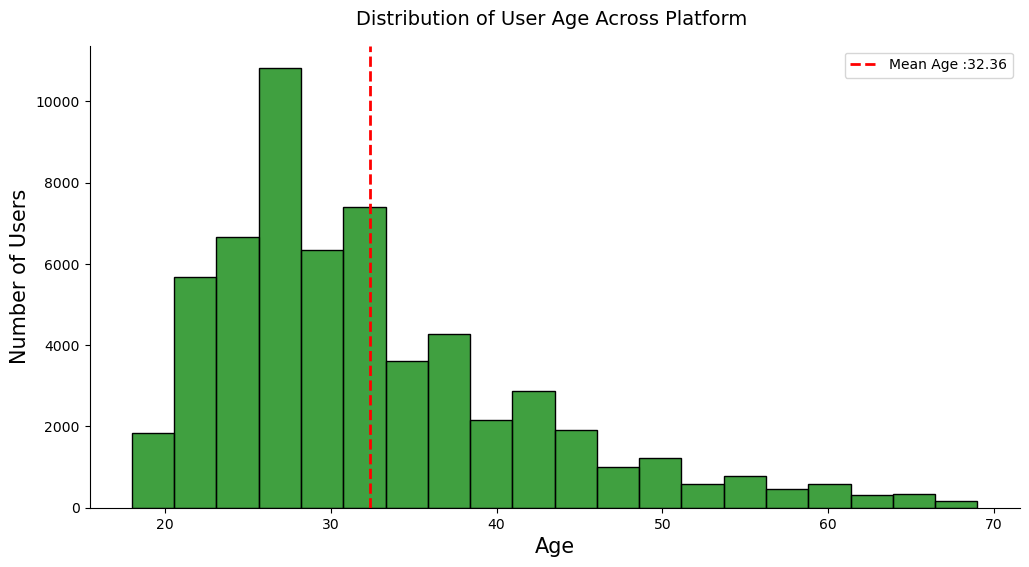

In [644]:
plt.figure(figsize=(12,6))
sns.histplot(data=df,x='age',bins=20,color='green',edgecolor='black')

mean_age = df['age'].mean().round(2)
# median_age = df['age'].median()
# mode_age = df['age'].mode()
# q1_age = df['age'].quantile(.25)
# q3_age = df['age'].quantile(.75)

plt.axvline(mean_age,color='red',linestyle='--',linewidth=2,label=(f'Mean Age :{mean_age}'))
# plt.axvline(median_age,color='blue',linestyle='--',linewidth=2,label=(f'Median Age :{median_age}'))
# plt.axvline(mode_age,color='red',linestyle='--',linewidth=2,label=(f'Mode Age :{mode_age}'))
# plt.axvline(q1_age,color='purple',linestyle='--',linewidth=2,label=(f'Q1 Age :{q1_age}'))
# plt.axvline(q3_age,color='yellow',linestyle='--',linewidth=2,label=(f'Q3 Age :{q3_age}'))

plt.title('Distribution of User Age Across Platform ', fontsize=14, pad=15)
plt.xlabel('Age',fontsize=15)
plt.ylabel('Number of Users',fontsize=15)
plt.legend()
sns.despine()
plt.show()

## Q1.2
How does the age distribution differ by gender? Are there age groups where one gender is more prevalent?

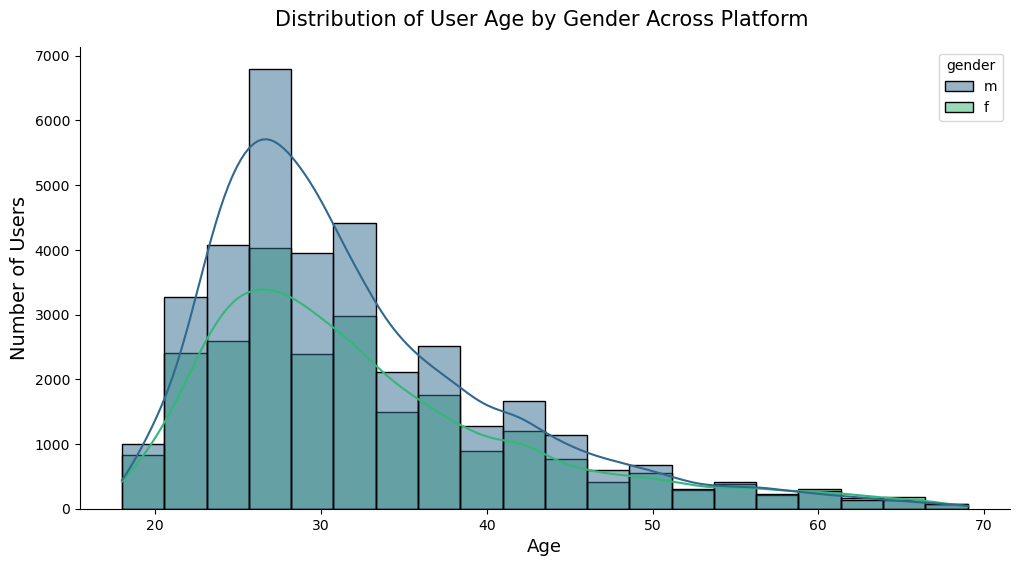

In [661]:
plt.figure(figsize=(12,6))
sns.histplot(data=df,x='age',hue='gender',kde=True,bins=20,palette='viridis',multiple='layer',alpha=0.5)

plt.title('Distribution of User Age by Gender Across Platform ', fontsize=15, pad=15)
plt.xlabel('Age',fontsize=13)
plt.ylabel('Number of Users',fontsize=14)
# plt.legend('gender')
sns.despine()
plt.show()

## 2. Income and Age
Visualizing the relationship between income and age helps uncover patterns in reported income levels across age groups, which could inform user segmentation strategies.

## Q2.1
Use a scatterplot to visualize the relationship between income and age, with a trend line indicating overall patterns. Are older users more likely to report higher incomes?



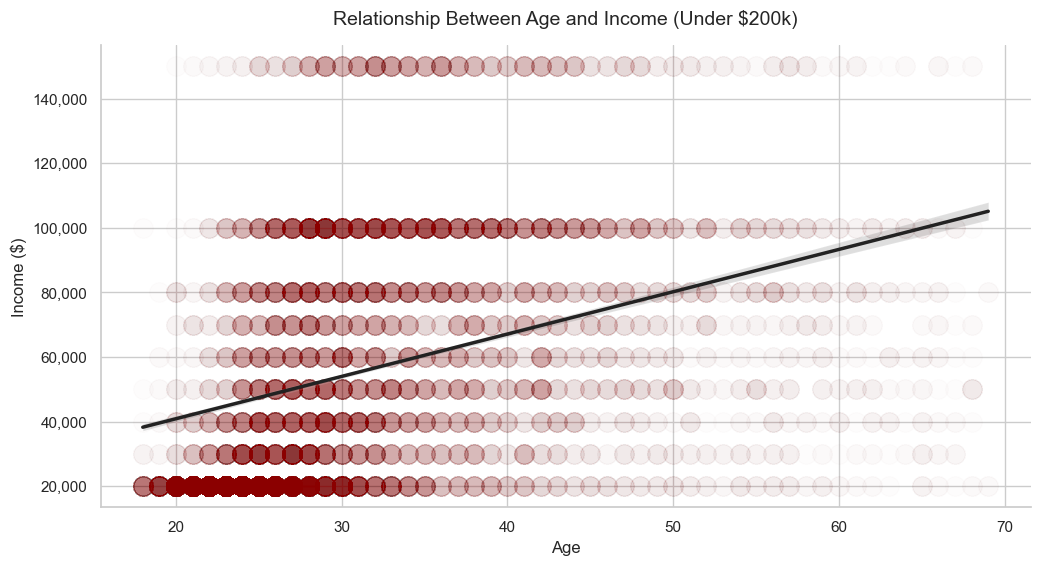

In [664]:
plt.figure(figsize=(12, 6))

# Let regplot handle BOTH the scatter points and the trendline together
sns.regplot(
    data=df, 
    x='age', 
    y='income', 
    color='#222222',                       # Color of the trendline
    line_kws={'linewidth': 2.5},
    scatter_kws={
        'color': 'darkred',             # Moves your preferred dot color here
        's': 200,                       # Your preferred size
        'alpha': 0.01                   # Your preferred opacity
    }
)

# Clean up the y-axis formatting (removes scientific notation)
import matplotlib.ticker as ticker
plt.gca().yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

plt.title('Relationship Between Age and Income (Under $200k)', fontsize=14, pad=15)
plt.xlabel('Age', fontsize=12)
plt.ylabel('Income ($)', fontsize=12)

sns.despine()
plt.show()

## Q2.2
Create boxplots of income grouped by age_group. Which age group reports the highest median income?


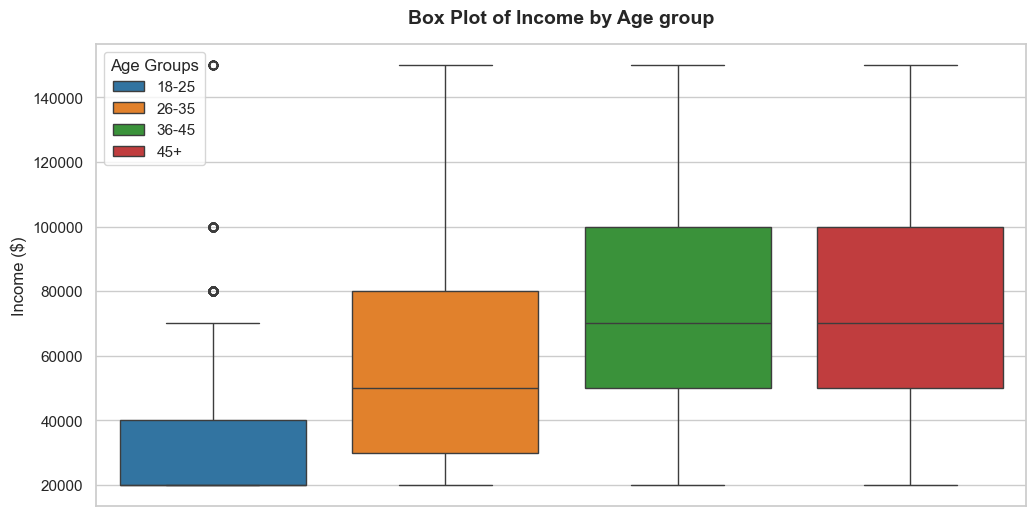

In [669]:
plt.figure(figsize=(12, 6))
ax = sns.boxplot(
    data=df, 
    x='age_group', 
    y='income',
    hue='age_group',
    palette = 'tab10',
    legend='full'

)

ax.set_xticklabels([])
plt.title('Box Plot of Income by Age group', fontsize=14, pad=15, weight = 'bold')
plt.ylabel('Income ($)', fontsize=12)
plt.xlabel('')
plt.legend(title='Age Groups')

## Q2.3
Analyze income levels within gender and status categories. For example, are single men more likely to report higher incomes than single women?


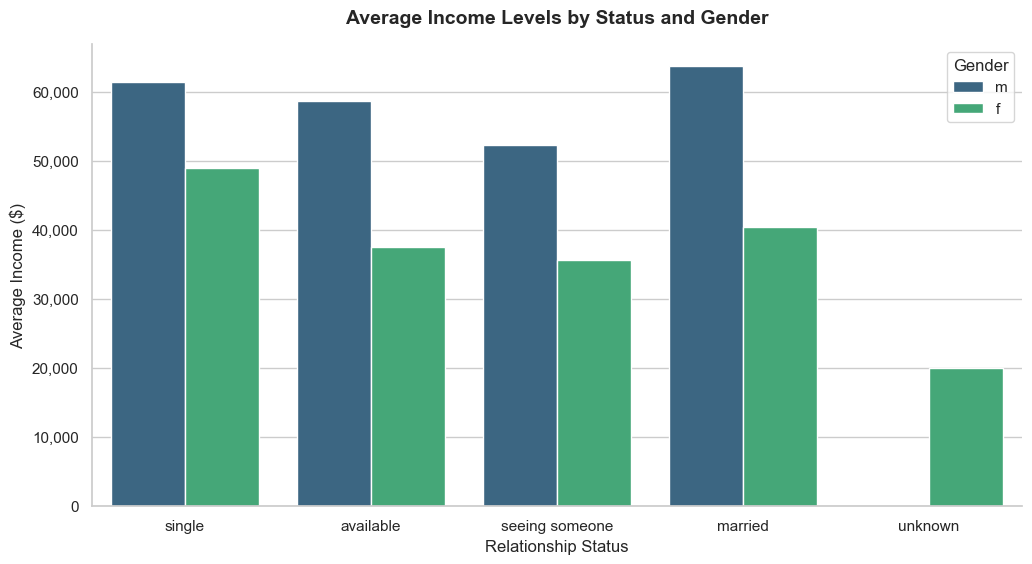

In [666]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x='status',
    y='income',
    hue='gender',
    palette='viridis',
    errorbar=None 
)

import matplotlib.ticker as ticker
plt.gca().yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

plt.title('Average Income Levels by Status and Gender', fontsize=14, pad=15, weight='bold')
plt.xlabel('Relationship Status', fontsize=12)
plt.ylabel('Average Income ($)', fontsize=12)
plt.legend(title='Gender')
sns.despine()
plt.show()

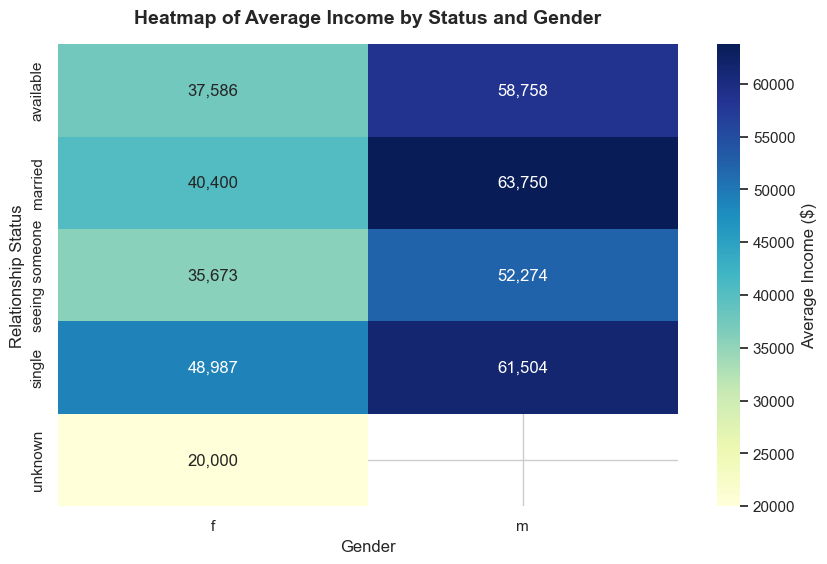

In [667]:
plt.figure(figsize=(10, 6))

# 1. Create a pivot table of average incomes
income_pivot = df.pivot_table(
    index='status', 
    columns='gender', 
    values='income', 
    aggfunc='mean'
)

# 2. Plot it as a heatmap
sns.heatmap(income_pivot, annot=True, fmt=",.0f", cmap='YlGnBu', cbar_kws={'label': 'Average Income ($)'})

plt.title('Heatmap of Average Income by Status and Gender', fontsize=14, pad=15, weight='bold')
plt.xlabel('Gender', fontsize=12)
plt.ylabel('Relationship Status', fontsize=12)
plt.show()


## 3. Pets and Preferences
Pets are often a key lifestyle preference and compatibility factor. Analyzing how pets preferences distribute across demographics can provide insights for filters or recommendations.

## Q3.1
Create a bar chart showing the distribution of pets categories (e.g., likes dogs, likes cats). Which preferences are most common?


In [674]:
df_pets = df.query("pets != 'Unknown'") #excluding Unknown for users who don't have any preference
pet_count = df_pets.pets.value_counts().reset_index()
pet_count

,pets,count
0,likes dogs and likes cats,14541
1,likes dogs,7125
2,likes dogs and has cats,4251
3,has dogs,4058
4,has dogs and likes cats,2297
5,likes dogs and dislikes cats,2000
6,has dogs and has cats,1441
7,has cats,1384
8,likes cats,1055
9,has dogs and dislikes cats,535


C:\Users\welcome\AppData\Local\Temp\ipykernel_18368\1918305156.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=pet_count,x='pets',y='count',palette='coolwarm')


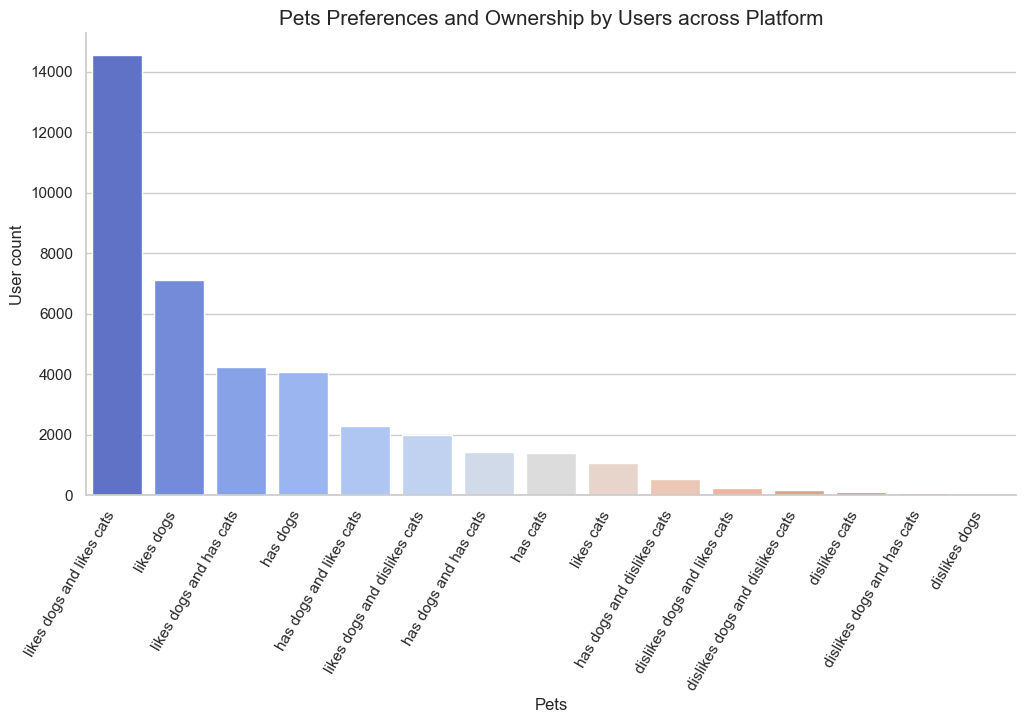

In [703]:
# For those Users who have a preference about pets
plt.figure(figsize=(12,6))
sns.barplot(data=pet_count,x='pets',y='count',palette='coolwarm')
plt.title("Pets Preferences and Ownership by Users across Platform",fontsize = 15)
plt.xlabel('Pets')
plt.ylabel('User count')
plt.xticks(rotation = 60,ha='right')
sns.despine()
plt.show()

C:\Users\welcome\AppData\Local\Temp\ipykernel_18368\845259624.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_pets_unknown,x='pets',y='count',palette='coolwarm')


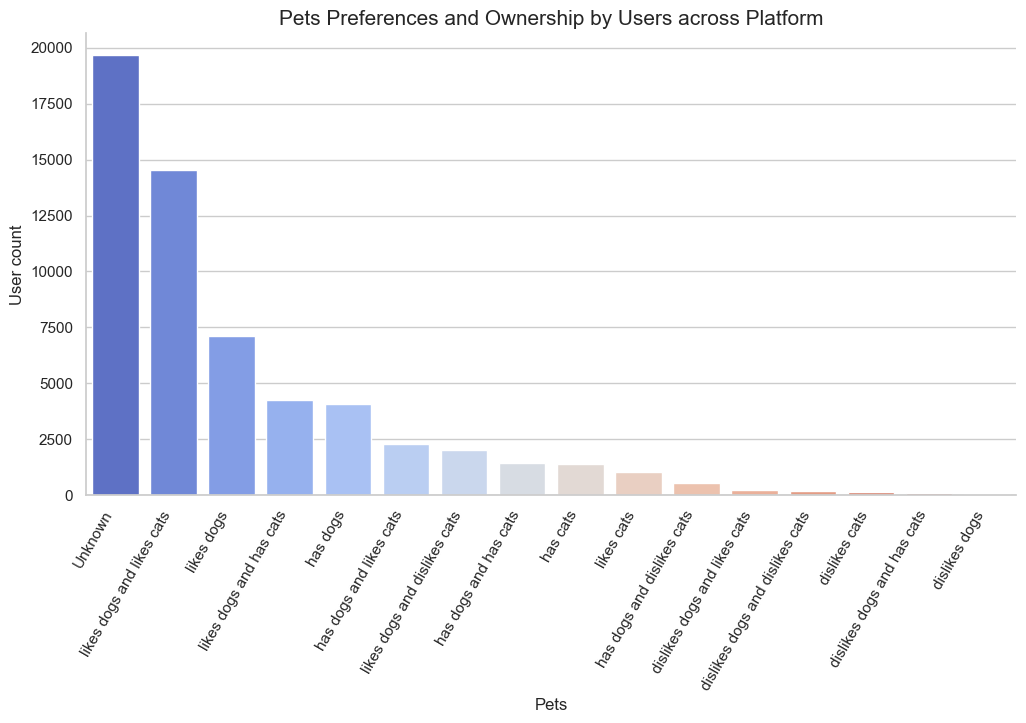

In [704]:
df_pets_unknown = df.pets.value_counts().reset_index()


plt.figure(figsize=(12,6))
sns.barplot(data=df_pets_unknown,x='pets',y='count',palette='coolwarm')
plt.title("Pets Preferences and Ownership by Users across Platform",fontsize = 15)
plt.xlabel('Pets')
plt.ylabel('User count')
plt.xticks(rotation = 60,ha='right')
sns.despine()
plt.show()

In [715]:
# Creating a copy of Data Frame to create new columns
df1 = df.copy()

In [716]:
# Creating individual columns
df1['likes cats'] = df1['pets'].str.contains('likes cats', na=False)
df1['likes dogs'] = df1['pets'].str.contains('likes dogs', na=False)

df1['dislikes cats'] = df1['pets'].str.contains('dislikes cats', na=False)
df1['dislikes dogs'] = df1['pets'].str.contains('dislikes dogs', na=False)

df1['has cats'] = df1['pets'].str.contains('has cats', na=False)
df1['has dogs'] = df1['pets'].str.contains('has dogs', na=False)


df1[['likes dogs', 'likes cats', 'has dogs', 'has cats', 'dislikes cats', 'dislikes dogs']].head()

,likes dogs,likes cats,has dogs,has cats,dislikes cats,dislikes dogs
0,True,True,False,False,False,False
1,True,True,False,False,False,False
2,False,False,False,True,False,False
3,False,True,False,False,False,False
4,True,True,False,False,False,False


In [717]:
pet_columns = ['likes dogs', 'likes cats', 'has dogs', 'has cats', 'dislikes cats', 'dislikes dogs']

individual_counts=df1[pet_columns].sum().reset_index()

individual_counts


,index,0
0,likes dogs,28449
1,likes cats,20958
2,has dogs,8331
3,has cats,7155
4,dislikes cats,2835
5,dislikes dogs,532


In [718]:
# Reseting column names
individual_counts.columns = ['Preference', 'Count']
individual_counts

,Preference,Count
0,likes dogs,28449
1,likes cats,20958
2,has dogs,8331
3,has cats,7155
4,dislikes cats,2835
5,dislikes dogs,532


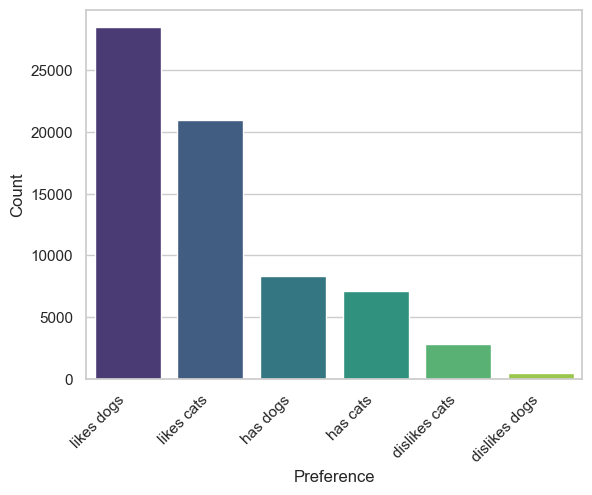

In [719]:
# Creating bar plot
sns.barplot(
    data= individual_counts,
    x = 'Preference',
    y = 'Count',
    hue= 'Preference',
    palette = 'viridis'
)

plt.xticks(rotation=45, ha='right')

plt.show()

In [720]:
# Sorting based on counts

individual_counts_sorted = individual_counts.sort_values('Count',ascending=False)
individual_counts_sorted

,Preference,Count
0,likes dogs,28449
1,likes cats,20958
2,has dogs,8331
3,has cats,7155
4,dislikes cats,2835
5,dislikes dogs,532


C:\Users\welcome\AppData\Local\Temp\ipykernel_18368\2359925973.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=individual_counts_sorted, x='Count', y='Preference', palette='coolwarm')


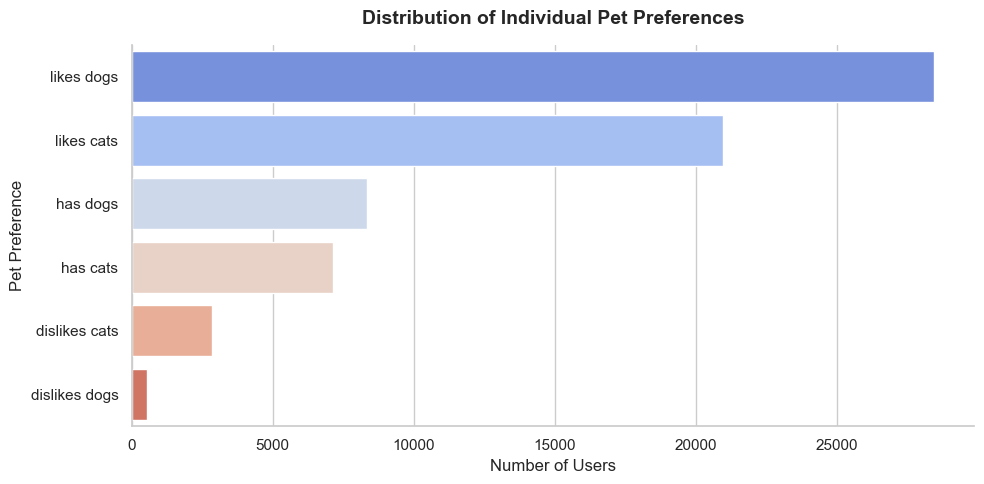

In [721]:
# Creating a sorted column chart


plt.figure(figsize=(10, 5))
sns.barplot(data=individual_counts_sorted, x='Count', y='Preference', palette='coolwarm')

# Formatting labels and title
plt.title('Distribution of Individual Pet Preferences', fontsize=14, pad=15, weight='bold')
plt.xlabel('Number of Users', fontsize=12)
plt.ylabel('Pet Preference', fontsize=12)

sns.despine()
plt.tight_layout()
plt.show()


## Q3.2
How do pets preferences vary across gender and age_group? Are younger users more likely to report liking pets compared to older users?

In [722]:
#calculating the proportion of each 
gender_pets = df1.groupby('gender')[['likes dogs', 'likes cats', 'has dogs', 'has cats','dislikes dogs','dislikes cats']].mean()*100
# converting it into percentage
gender_pets


,likes dogs,likes cats,has dogs,has cats,dislikes dogs,dislikes cats
gender,,,,,,
f,48.405833,34.026994,17.909824,17.809536,0.910952,5.728971
m,48.077197,36.531828,11.531115,8.247099,0.895122,4.173437


In [731]:
#Converting to Stacked data format

gender_pets = gender_pets.reset_index().melt(id_vars='gender', var_name='Preference', value_name='Percentage')
gender_pets

,gender,Preference,Percentage
0,f,likes dogs,48.405833
1,m,likes dogs,48.077197
2,f,likes cats,34.026994
3,m,likes cats,36.531828
4,f,has dogs,17.909824
5,m,has dogs,11.531115
6,f,has cats,17.809536
7,m,has cats,8.247099
8,f,dislikes dogs,0.910952
9,m,dislikes dogs,0.895122


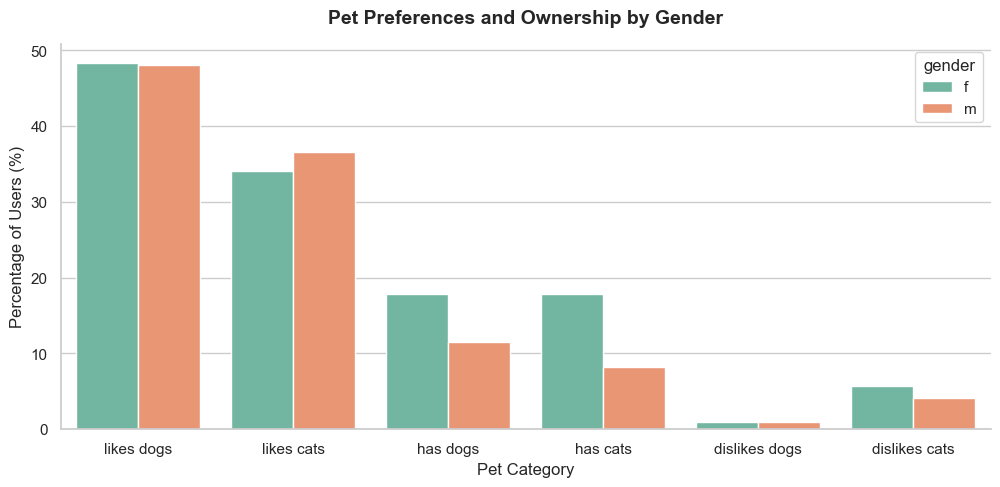

In [728]:
# Plotting the bar plot

plt.figure(figsize=(12, 5))
sns.barplot(data=gender_pets, x='Preference', y='Percentage', hue='gender', palette='Set2')
plt.title('Pet Preferences and Ownership by Gender', fontsize=14, pad=15, weight='bold')
plt.ylabel('Percentage of Users (%)', fontsize=12)
plt.xlabel('Pet Category', fontsize=12)
sns.despine()
plt.show()

In [732]:
# Calculate the percentage of pet preferences by Age Group

age_pets = df1.groupby('age_group', observed=False)[['likes dogs', 'likes cats', 'has dogs', 'has cats','dislikes dogs','dislikes cats']].mean() * 100
age_pets = age_pets.reset_index().melt(id_vars='age_group', var_name='Preference', value_name='Percentage') 

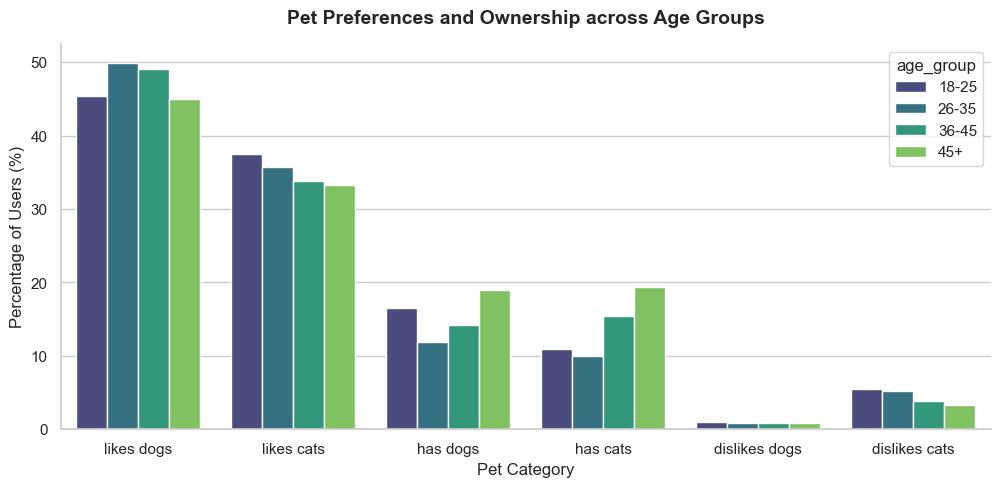

In [733]:
# Plot Age Group vs Pet Preferences

plt.figure(figsize=(12, 5))
sns.barplot(data=age_pets, x='Preference', y='Percentage', hue='age_group', palette='viridis')
plt.title('Pet Preferences and Ownership across Age Groups', fontsize=14, pad=15, weight='bold')
plt.ylabel('Percentage of Users (%)', fontsize=12)
plt.xlabel('Pet Category', fontsize=12)
sns.despine()
plt.show()

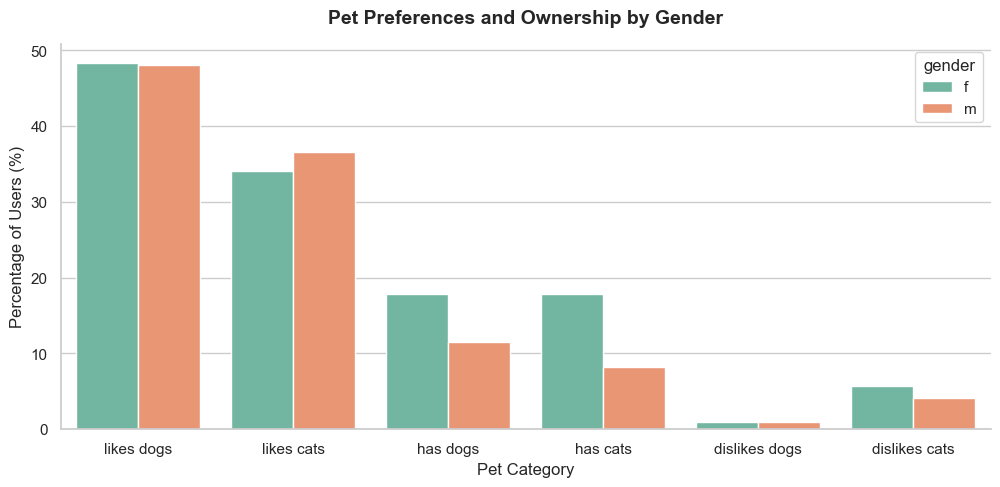

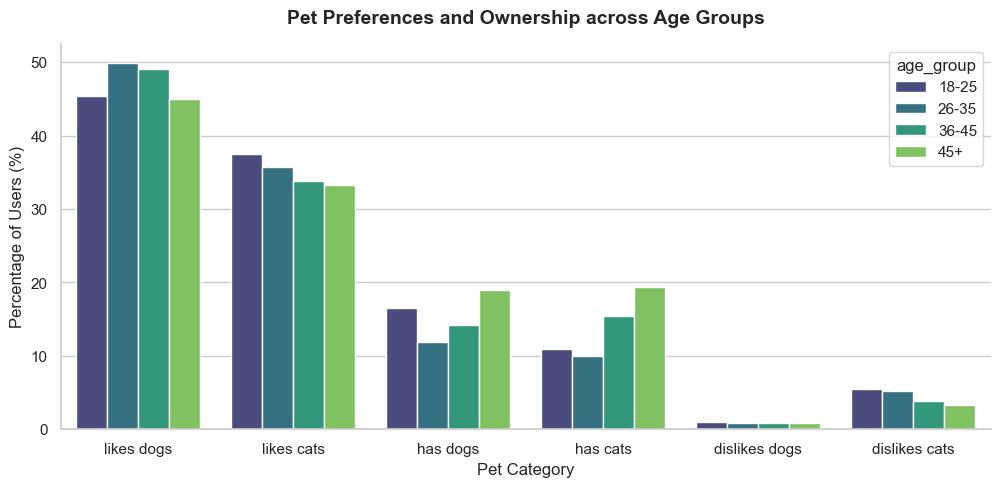

In [734]:
#Plotting graphs together

plt.figure(figsize=(12, 5))
sns.barplot(data=gender_pets, x='Preference', y='Percentage', hue='gender', palette='Set2')
plt.title('Pet Preferences and Ownership by Gender', fontsize=14, pad=15, weight='bold')
plt.ylabel('Percentage of Users (%)', fontsize=12)
plt.xlabel('Pet Category', fontsize=12)
sns.despine()
plt.show()
plt.figure(figsize=(12, 5))
sns.barplot(data=age_pets, x='Preference', y='Percentage', hue='age_group', palette='viridis')
plt.title('Pet Preferences and Ownership across Age Groups', fontsize=14, pad=15, weight='bold')
plt.ylabel('Percentage of Users (%)', fontsize=12)
plt.xlabel('Pet Category', fontsize=12)
sns.despine()
plt.show()


## 4. Signs and Personality
Users’ self-reported zodiac signs (sign) can offer insights into personality preferences or trends. While not scientifically grounded, analyzing this data helps explore fun and engaging patterns.

## Q4.1
Create a pie chart showing the distribution of zodiac signs (sign) across the platform. Which signs are most and least represented? Is this the right chart? If not, replace with right chart.


In [744]:
df.query("sign != 'Unknown'").sign.value_counts()#.reset_index()

sign
gemini and it&rsquo;s fun to think about         1763
scorpio and it&rsquo;s fun to think about        1740
leo and it&rsquo;s fun to think about            1669
taurus and it&rsquo;s fun to think about         1624
libra and it&rsquo;s fun to think about          1622
pisces and it&rsquo;s fun to think about         1571
cancer and it&rsquo;s fun to think about         1570
sagittarius and it&rsquo;s fun to think about    1557
aries and it&rsquo;s fun to think about          1551
virgo and it&rsquo;s fun to think about          1548
aquarius and it&rsquo;s fun to think about       1486
virgo but it doesn&rsquo;t matter                1481
leo but it doesn&rsquo;t matter                  1436
gemini but it doesn&rsquo;t matter               1431
taurus but it doesn&rsquo;t matter               1425
cancer but it doesn&rsquo;t matter               1423
aquarius but it doesn&rsquo;t matter             1385
libra but it doesn&rsquo;t matter                1381
capricorn and it&rsquo;

In [746]:
df['sign_fixed'] = df['sign'].str.replace('&rsquo;',"'")
df['sign_fixed'].value_counts()

sign_fixed
Unknown                                    10873
gemini and it's fun to think about          1763
scorpio and it's fun to think about         1740
leo and it's fun to think about             1669
taurus and it's fun to think about          1624
libra and it's fun to think about           1622
pisces and it's fun to think about          1571
cancer and it's fun to think about          1570
sagittarius and it's fun to think about     1557
aries and it's fun to think about           1551
virgo and it's fun to think about           1548
aquarius and it's fun to think about        1486
virgo but it doesn't matter                 1481
leo but it doesn't matter                   1436
gemini but it doesn't matter                1431
taurus but it doesn't matter                1425
cancer but it doesn't matter                1423
aquarius but it doesn't matter              1385
libra but it doesn't matter                 1381
capricorn and it's fun to think about       1362
sagittari

In [751]:
# Extract the first word as the zodiac sign
df['just_sign'] = df['sign_fixed'].str.strip().str.lower().str.split().str[0]


df[['sign', 'just_sign']].head(10)

,sign,just_sign
0,gemini,gemini
1,cancer,cancer
2,pisces but it doesn&rsquo;t matter,pisces
3,pisces,pisces
4,aquarius,aquarius
5,taurus,taurus
6,virgo,virgo
7,sagittarius,sagittarius
8,gemini but it doesn&rsquo;t matter,gemini
9,cancer but it doesn&rsquo;t matter,cancer


In [752]:
df.just_sign.value_counts()

just_sign
unknown        10873
leo             4313
gemini          4247
libra           4131
cancer          4126
virgo           4083
taurus          4071
scorpio         4062
aries           3933
pisces          3889
sagittarius     3882
aquarius        3878
capricorn       3522
Name: count, dtype: int64

In [756]:
# Filtering those users who didn't shared their Zodiac sign
df_zodiac_sign = df.query('sign != "Unknown"')
df_zodiac_sign.head(1)

,age,status,gender,body_type,diet,drinks,education,ethnicity,height,income,...,sign,speaks,age_group,income_group,profile_completeness,height_cm,city,state,sign_fixed,just_sign
0,22,single,m,a little extra,strictly anything,socially,working on college/university,"asian, white",75.0,NaN,...,gemini,english,18-25,NaN,90.0,190.5,south san francisco,california,gemini,gemini


In [757]:
sign_counts = df_zodiac_sign['just_sign'].value_counts().sort_values(ascending=False)

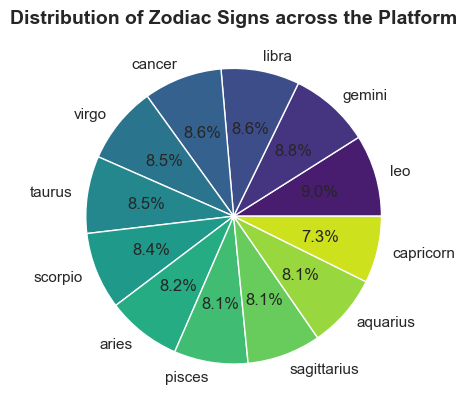

In [758]:
plt.pie(
    sign_counts.values, 
    labels=sign_counts.index, 
    autopct='%1.1f%%', 
    #startangle=140, 
    colors=sns.color_palette('viridis', len(sign_counts)) # Feeding Seaborn colors into it
)

plt.title('Distribution of Zodiac Signs across the Platform', fontsize=14, weight='bold')
plt.show()

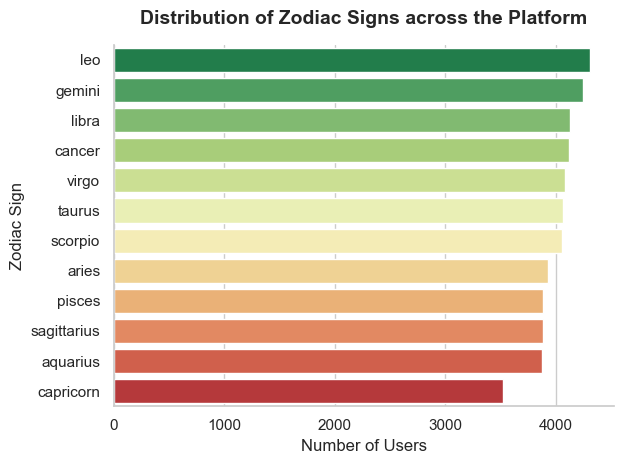

In [759]:
sns.barplot(x=sign_counts.values, y=sign_counts.index, palette='RdYlGn_r', hue=sign_counts.index, legend=False)
plt.title('Distribution of Zodiac Signs across the Platform', fontsize=14, pad=15, weight='bold')
plt.xlabel('Number of Users', fontsize=12)
plt.ylabel('Zodiac Sign', fontsize=12)
sns.despine()
plt.tight_layout()
plt.show()


## Q4.2
How does sign vary across gender and status? Are there noticeable patterns or imbalances?

In [761]:
cross_tab_gen_sign = (pd.crosstab(df_zodiac_sign['gender'], df_zodiac_sign['just_sign'], normalize='index') * 100).round(2)

cross_tab_gen_sign

just_sign,aquarius,aries,cancer,capricorn,gemini,leo,libra,pisces,sagittarius,scorpio,taurus,virgo
gender,,,,,,,,,,,,
f,8.12,8.38,8.44,7.57,8.71,8.74,8.41,8.09,8.47,8.20,8.32,8.55
m,8.01,8.01,8.67,7.13,8.90,9.12,8.70,8.07,7.77,8.61,8.56,8.43


In [762]:
sign_sentiment_melted = cross_tab_gen_sign.reset_index().melt(
    id_vars='gender', 
    var_name='Sign', 
    value_name='Percentage'
)

sign_sentiment_melted.head(5)

,gender,Sign,Percentage
0,f,aquarius,8.12
1,m,aquarius,8.01
2,f,aries,8.38
3,m,aries,8.01
4,f,cancer,8.44


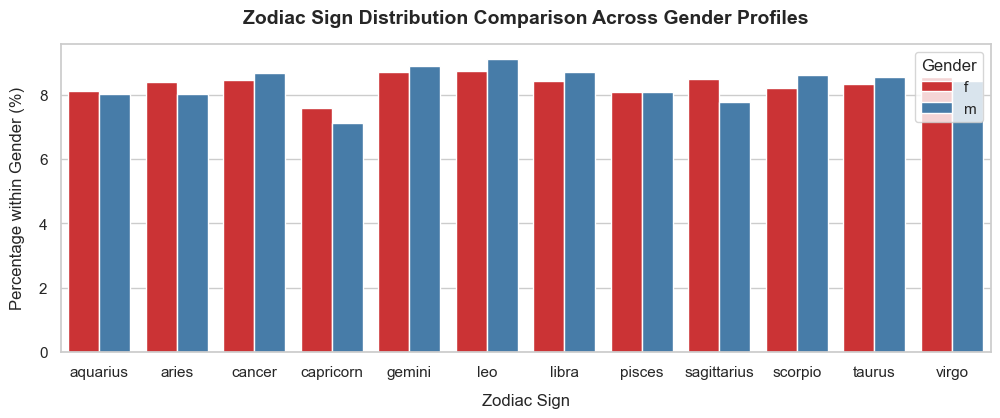

In [774]:
plt.figure(figsize=(12, 4))
sns.barplot(
    data = sign_sentiment_melted,
    x='Sign',
    y='Percentage',
    hue='gender',
    palette = 'Set1'
)

plt.title('Zodiac Sign Distribution Comparison Across Gender Profiles', fontsize=14, pad=15, weight='bold')
plt.xlabel('Zodiac Sign', fontsize=12, labelpad=10)
plt.ylabel('Percentage within Gender (%)', fontsize=12, labelpad=10)

plt.legend(title='Gender')
plt.show()

---

# **Part 1: Data Cleaning (Missing Data, Dtypes & Outliers)**

## **1. Output Summary & Analytical Logic**
- **Missingness & Sentinel Values:** Lifestyle and personal columns had the highest missing rates: `income` (80.81% disguised as `-1`), `diet` (40.69%), `religion` (33.74%), `pets` (33.23%), `sign` (18.44%), `job` (13.68%), and `education` (11.06%). Replacing `-1` in `income` with `NaN` and filling categorical nulls with `"Unknown"` preserved 59,010 user rows without fabricating synthetic personal traits.
- **Domain-Driven Outlier Treatment:** A blind 1.5 × IQR rule on `age` set the upper fence at 53.5 years, which would have wiped out 2,638 legitimate older daters. Inspecting unique values isolated the actual joke entries (`109` and `110`) and preserved the 18–70 range. For `height` (97 rows outside 58–78 inches) and `income` (718 rows above `$220,000`), trimming extreme tails removed <1.5% of the data to prevent mean distortion.

## **2. Data Limitations & Critical Skepticism**
- **Legacy Pipeline Bug (`-1` in Income):** Storing missing income as `-1` is a classic legacy database export artifact where a numeric integer column could not accept `NULL` values.
- **Self-Reporting & Fixed-Dropdown Bias:** Unique values in `income` (`$20,000`, `$80,000`, `$1,000,000`) and `education` (`"working on space camp"`) show that users selected from pre-set dropdown brackets—some of which included humorous or troll options—rather than verified financial or academic data.
- **Temporal Stagnation (`last_online`):** All `last_online` timestamps cluster around June 2012 (`2012-06`), proving this is a static historical snapshot (likely an early regional cohort) rather than a live, rolling production database.

## **3. What is Limiting Growth?**
- **Onboarding Friction & Filter Starvation:** When 33%–81% of users skip `income`, `diet`, `religion`, and `pets`, the matchmaking engine lacks the metadata needed for collaborative filtering. Furthermore, Bumble monetises heavily via Paid Advanced Filters; if a paying subscriber filters for a "Vegetarian who likes dogs," they automatically exclude >50% of the user base who left those fields blank, resulting in empty swipe decks and subscription churn.

## **4. Recommendations**
1. **Fix Database Schema & Input Validation:** Enforce `NULL` support in backend numeric fields (eliminating `-1` sentinel bugs) and restrict `height` inputs to realistic slider bounds (4 ft 10 in to 6 ft 8 in) at signup.
2. **Gamify Optional Profile Prompts:** Replace tedious text and dropdown forms during onboarding with quick-tap visual badges (e.g., Diet, Pets, Zodiac) prompted progressively over a user's first 3 days on the app.

---

# **Part 2: Data Processing (Binning, Derived Features & Units)**

## **1. Output Summary & Analytical Logic**
- **Age Binning (`age_group`):** The platform is heavily anchored by Mid-Career Adults (`26–35` at 47.77% / 28,189 users) and Young Adults (`18–25` at 24.02% / 14,175 users), while `36–45` (18.05% / 10,649 users) and `45+` (10.16% / 5,997 users) represent a smaller tail.
- **Income Grouping (`income_group`):** Among the ~19% of users who disclosed income, Medium Income dominates (51.9% / 5,558 users), followed by Low Income (27.3% / 2,927 users) and High Income (20.9% / 2,237 users).
- **Profile Completeness (`profile_completeness`):** Overall completeness averages ~80% across age and gender, but drops sharply to 60.95% among users with `"Unknown"` jobs and 74.00% among users with `"unknown"` relationship status.

## **2. Data Limitations & Critical Skepticism**
- **Selection Bias in Income Brackets:** Because >80% of users hid their income, the `income_group` distribution only reflects the 10,722 users willing to disclose earnings. Lower-earning students (`$20,000`) or high earners (`$150,000+`) may disproportionately hide or state their income, skewing the quartiles.
- **Completeness Formula Inflation:** Because mandatory signup fields (`age`, `gender`, `height`, `speaks`) have nearly 0% missingness, every user starts with a baseline of 40% completeness. Additionally, users with an assigned `income_group` show >91% completeness partly because having a non-null `income` automatically boosts their score by +10%.

## **3. What is Limiting Growth?**
- **Low-Effort "Ghost" Profiles:** The cluster of users with `"Unknown"` jobs and ~60% profile completeness represents low-intent or privacy-guarded accounts. In a dating marketplace, bare-bones profiles receive significantly fewer right-swipes and messages, leading to early user frustration and Day-7 churn.
- **Under-Penetration in Gen-Z (`18–25`) & Mature (`36+`) Tiers:** Having nearly half the platform locked into `26–35` limits viral top-of-funnel growth (driven by college-aged `18–25` users) and leaves revenue on the table in the `36+` bracket, where disposable income is highest.

## **4. Recommendations**
1. **"Give-to-Get" Filter Gating:** Require users to maintain at least 80% profile completeness—or fill in a specific badge like `job` or `education`—before they are allowed to filter other users by that same attribute.
2. **Tiered Monetisation by Age Cohort:** Offer discounted student and micro-transaction bundles (e.g., single SuperSwipes or Spotlights) for the `18–25` Low-Income cohort, while pitching annual Bumble Premium memberships to the `26–45+` Medium and High-Income cohorts.

---

# **Part 3: Data Analysis (Demographics, Correlations, Lifestyle & Geography)**

## **1. Output Summary & Analytical Logic**
- **Gender & Status (Q1.1–1.3):** Men account for 59.45% (35,079) vs. 40.55% (23,931) for women. While 92.95% of users are `single`, 7.05% (4,163 users) list `seeing someone` (3.43%), `available` (3.09%), or `married` (0.52%). Women have a slightly higher rate of `seeing someone` (4.12%) than men (2.96%).
- **Correlations (Q2.1):** `age` and `income` show a moderate positive correlation (r = 0.353), confirming earnings rise with career seniority. `height` and `income` show a weak positive correlation (r = 0.139), while `age` and `height` are uncorrelated (r = -0.023).
- **Lifestyle & Geography (Q3–Q4):** Social drinking is the dominant lifestyle trait, while dietary preferences are largely unspecified or flexible (`"anything"`). Geographically, 99.85% of users are located in California (concentrated around San Francisco, Oakland, and Berkeley).

## **2. Data Limitations & Critical Skepticism**
- **The 99.85% California Artifact (Cohort & Sampling Bias):** Having 99.85% of users in California does not mean Bumble only operates in one state; rather, this dataset is a localized historical extract from the San Francisco Bay Area (the initial tech-hub launch market). The remaining 0.15% outside California likely represent Bay Area users who travelled or relocated after creating their accounts.
- **Confounding Variable in Height vs. Income (r = 0.139):** Taller people do not inherently earn more money on Bumble; rather, `gender` is a confounding variable. Men make up 59.45% of the dataset, are physically taller on average, and report higher incomes in this sample, creating a statistical illusion of height-income correlation.

## **3. What is Limiting Growth?**
- **The 60:40 Gender Bottleneck:** A nearly 6:4 male-to-female ratio is the single biggest threat to retention. Male users face intense competition and low match rates (causing paid subscriber churn), while female users face notification overload (causing app fatigue).
- **Hyper-Local Concentration Risk:** If a platform's active user density is restricted to one metropolitan hub (California / Bay Area), network effects break down whenever users travel, commute, or move to Tier-2 cities or neighbouring states, resulting in "empty radar" churn.
- **Relationship Intent Contamination:** Mixing 4,163 `married`, `seeing someone`, and `available` users into the same swipe pool as 54,847 `single` users creates trust friction and mismatched expectations for users seeking exclusive relationships.

## **4. Recommendations**
1. **Rebalance Gender Liquidity:** Reallocate performance marketing budgets toward female-first acquisition (women-focused events, safety features, referral perks) and introduce daily right-swipe limits for free-tier male users to improve match quality.
2. **Geographic Expansion Playbook:** Replicate the high-density Bay Area cluster model city-by-city (e.g., New York, Austin, Chicago) rather than spreading marketing thin nationally, ensuring local liquidity crosses the critical mass threshold before moving to the next metro.
3. **Strict Intent Segmentation:** Separate non-single users (`married`, `seeing someone`) into dedicated Bumble BFF (platonic friendships) or Ethical Non-Monogamy / Casual filter lanes so core `single` daters are not blindsided.

---

# **Part 4: Data Visualization & Cross-Segment Synthesis**

## **1. Output Summary & Analytical Logic**
- **Visualizing Distributions (Histograms & Boxplots):** Visualising `age`, `height`, and `income` via boxplots and bar charts immediately exposes right-skewness in `age` (peaking at 26–35) and `income` (heavily right-skewed with a long high-earner tail), justifying the use of medians and IQR over means and standard deviations.
- **Bivariate & Heatmap Visuals:** Missing-value heatmaps visually prove that missingness is not random—users who skip `diet` frequently skip `religion` and `pets` simultaneously. Cross-tab visuals of lifestyle habits by age group show social drinking peaking in the 18–35 cohorts and moderating in the 45+ bracket.

## **2. Data Limitations & Critical Skepticism**
- **Survivorship & Static Snapshot Bias:** Visualising user counts by age or lifestyle only shows registered profiles, not active daily engagement. Without plotting `last_online` recency or match conversion rates alongside these distributions, a large bar on a chart could include thousands of dormant accounts.
- **Text Noise in Categorical Visuals:** Raw columns like `sign`, `religion`, and `speaks` contain modifiers (e.g., `"pisces but it doesn't matter"`, `"english (fluently), c++"`), which fragment bar charts into dozens of noisy sub-categories unless stripped down to their root values first.

## **3. What is Limiting Growth?**
- **Unstructured Text Hurts Matching Precision:** Because attributes like `religion`, `sign`, and `speaks` allow free-form or multi-clause strings (including joke languages like `"c++"`), simple exact-match algorithms fail to pair compatible users (e.g., failing to match `"agnosticism"` with `"agnosticism and very serious about it"`).

## **4. Recommendations**
1. **Standardize Taxonomies into Two-Tier Tags:** Split messy composite strings into two clean database fields: Core Attribute (e.g., `Religion: Agnostic`, `Sign: Pisces`) and Importance Weight (`Low / Medium / High`), allowing both cleaner analytics visuals and weighted algorithmic matching.
2. **Track Active Cohort Health Over Raw Signups:** Pair demographic visuals with a `days_since_last_online` metric on executive dashboards so product teams track Active Gender Ratio and Active Regional Density rather than vanity registration totals.